### 1. Импорты

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import torch
import numpy as np

import json
import platform
import random

import torchvision
from torch import nn

# Определяем корень проекта diplom_project
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    if (PROJECT_ROOT.parent / "src").exists():
        PROJECT_ROOT = PROJECT_ROOT.parent
    else:
        raise FileNotFoundError(
            "Не удалось найти папку src. "
            "Открой notebook внутри проекта diplom_project."
        )

# Добавляем корень проекта в путь Python
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data import CLASS_NAMES, load_fashion_mnist, create_train_validation_split, calculate_train_mean_std, create_normalized_transform

from src.model import FashionCNN, count_trainable_parameters

print("Корень проекта:", PROJECT_ROOT)
print("Классы:", CLASS_NAMES)

Корень проекта: d:\Учеба\fashion-mnist-cnn-experiments
Классы: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### 2. Загрузка датасета

In [2]:
full_train_dataset, test_dataset = load_fashion_mnist()

print("Размер обучающей выборки:", len(full_train_dataset))
print("Размер тестовой выборки:", len(test_dataset))

Размер обучающей выборки: 60000
Размер тестовой выборки: 10000


### 3. Проверка одного изображения

In [3]:
image, label = full_train_dataset[0]

label = int(label)

print("Тип изображения:", type(image))
print("Размер изображения:", image.shape)
print("Тип данных:", image.dtype)
print("Минимальное значение:", image.min().item())
print("Максимальное значение:", image.max().item())
print("Числовая метка:", label)
print("Название класса:", CLASS_NAMES[label])

assert image.shape == (1, 28, 28)
assert 0 <= label < 10
assert image.min() >= 0
assert image.max() <= 1

print("Проверка изображения пройдена")

Тип изображения: <class 'torch.Tensor'>
Размер изображения: torch.Size([1, 28, 28])
Тип данных: torch.float32
Минимальное значение: 0.0
Максимальное значение: 1.0
Числовая метка: 9
Название класса: Ankle boot
Проверка изображения пройдена


### 4. Проверка количества классов

In [4]:
print("Классы из датасета:")
print(full_train_dataset.classes)

print()
print("Наш список классов:")
print(CLASS_NAMES)

assert len(full_train_dataset.classes) == 10
assert full_train_dataset.classes == CLASS_NAMES

unique_labels = torch.unique(full_train_dataset.targets).tolist()

print("Уникальные метки:", unique_labels)

assert unique_labels == list(range(10))

Классы из датасета:
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

Наш список классов:
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Уникальные метки: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


### 5. Количество изображений каждого класса

In [5]:
train_labels = full_train_dataset.targets
test_labels = test_dataset.targets

train_counts = torch.bincount(
    train_labels,
    minlength=len(CLASS_NAMES),
)

test_counts = torch.bincount(
    test_labels,
    minlength=len(CLASS_NAMES),
)

print("Количество изображений в train:")
for class_id, count in enumerate(train_counts):
    print(f"{class_id}: {CLASS_NAMES[class_id]} — {int(count)}")

print()
print("Количество изображений в test:")
for class_id, count in enumerate(test_counts):
    print(f"{class_id}: {CLASS_NAMES[class_id]} — {int(count)}")

assert train_counts.sum().item() == 60000
assert test_counts.sum().item() == 10000
assert torch.all(train_counts == 6000)
assert torch.all(test_counts == 1000)

print("Распределение классов проверено")

Количество изображений в train:
0: T-shirt/top — 6000
1: Trouser — 6000
2: Pullover — 6000
3: Dress — 6000
4: Coat — 6000
5: Sandal — 6000
6: Shirt — 6000
7: Sneaker — 6000
8: Bag — 6000
9: Ankle boot — 6000

Количество изображений в test:
0: T-shirt/top — 1000
1: Trouser — 1000
2: Pullover — 1000
3: Dress — 1000
4: Coat — 1000
5: Sandal — 1000
6: Shirt — 1000
7: Sneaker — 1000
8: Bag — 1000
9: Ankle boot — 1000
Распределение классов проверено


### 6. График распределения классов

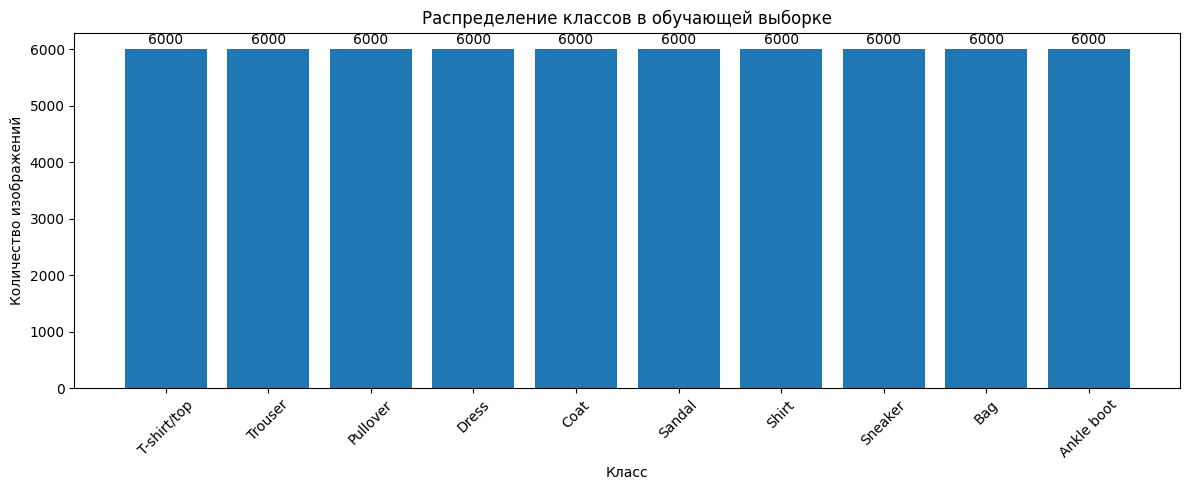

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(CLASS_NAMES, train_counts.numpy())

ax.set_title("Распределение классов в обучающей выборке")
ax.set_xlabel("Класс")
ax.set_ylabel("Количество изображений")
ax.tick_params(axis="x", rotation=45)

for bar, count in zip(bars, train_counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        str(int(count)),
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

### 7. Сетка первых 16 изображений

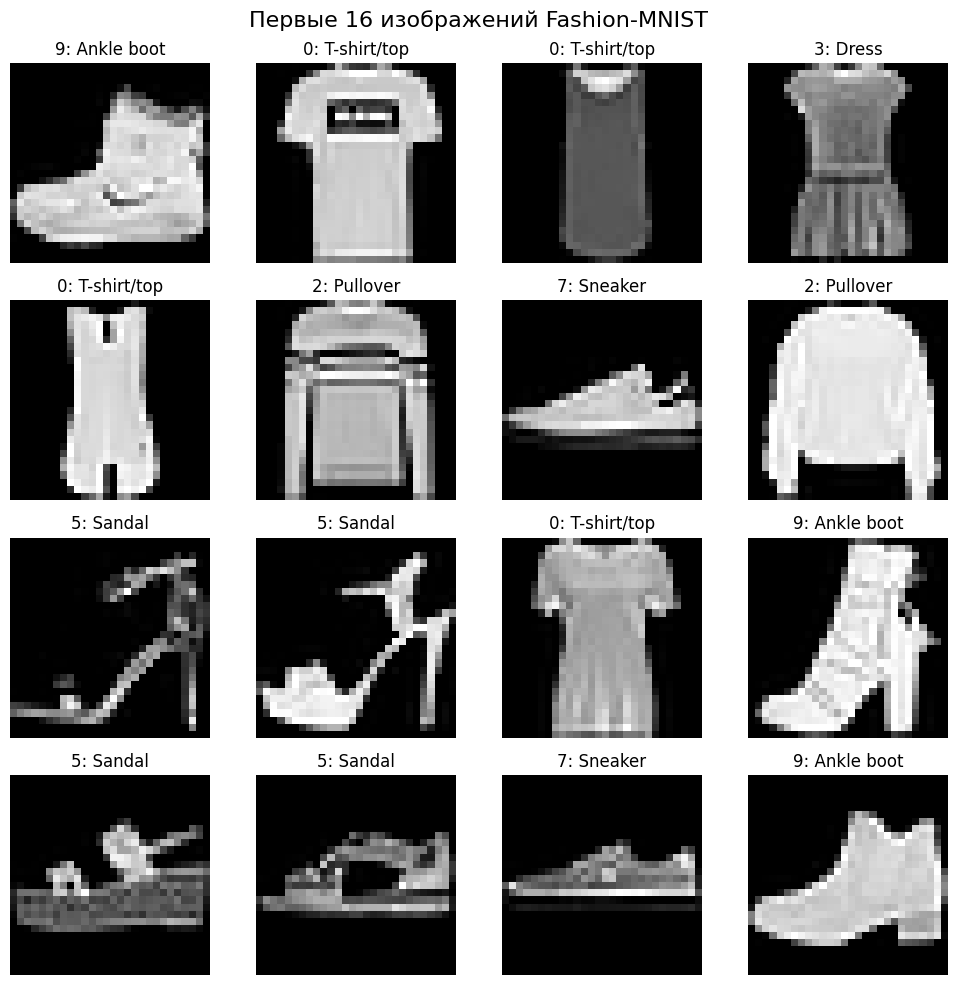

In [7]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for index, ax in enumerate(axes.ravel()):
    image, label = full_train_dataset[index]
    label = int(label)

    ax.imshow(image.squeeze().numpy(), cmap="gray")
    ax.set_title(f"{label}: {CLASS_NAMES[label]}")
    ax.axis("off")

fig.suptitle("Первые 16 изображений Fashion-MNIST", fontsize=16)
plt.tight_layout()
plt.show()

### 8. Случайные изображения

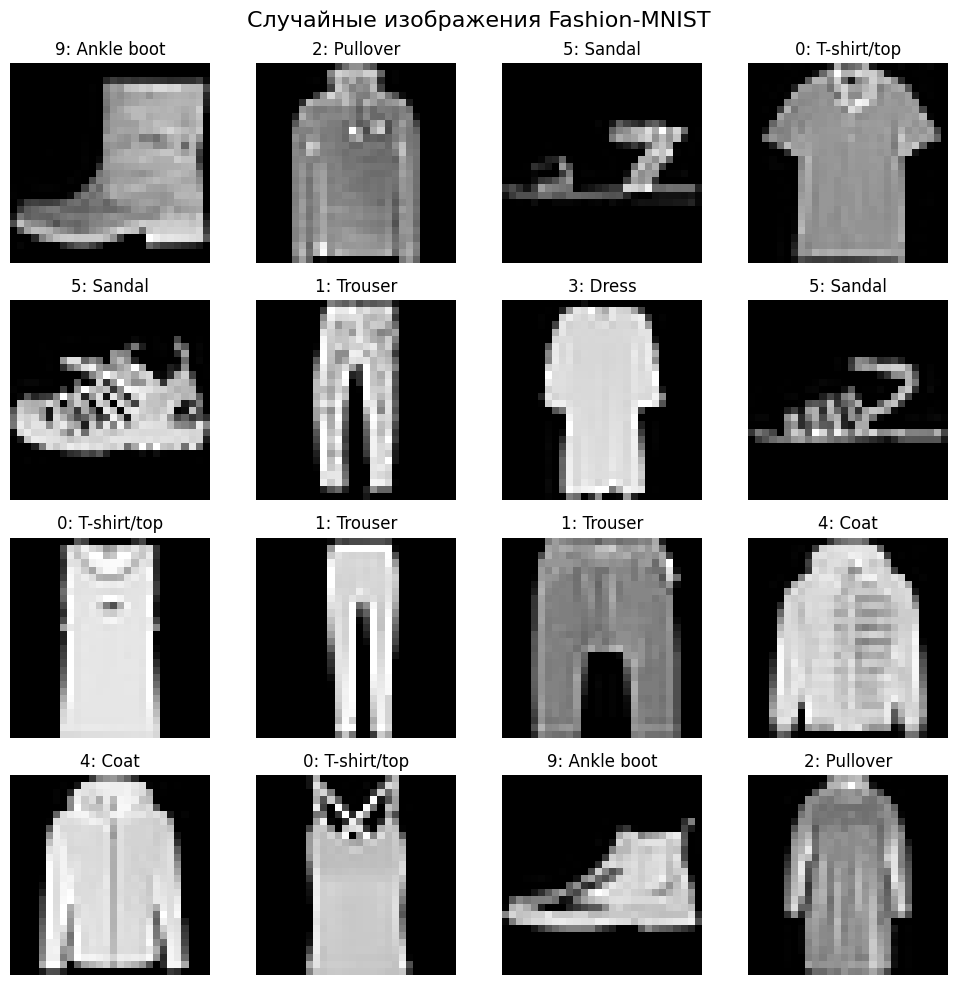

In [8]:
generator = torch.Generator()
generator.manual_seed(42)

random_indices = torch.randperm(
    len(full_train_dataset),
    generator=generator,
)[:16].tolist()

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for ax, index in zip(axes.ravel(), random_indices):
    image, label = full_train_dataset[index]
    label = int(label)

    ax.imshow(image.squeeze().numpy(), cmap="gray")
    ax.set_title(f"{label}: {CLASS_NAMES[label]}")
    ax.axis("off")

fig.suptitle("Случайные изображения Fashion-MNIST", fontsize=16)
plt.tight_layout()
plt.show()

In [9]:
print("Проверка этапа 3 завершена")
print(f"Train: {len(full_train_dataset)} изображений")
print(f"Test: {len(test_dataset)} изображений")
print(f"Размер одного изображения: {full_train_dataset[0][0].shape}")
print(f"Количество классов: {len(CLASS_NAMES)}")

Проверка этапа 3 завершена
Train: 60000 изображений
Test: 10000 изображений
Размер одного изображения: torch.Size([1, 28, 28])
Количество классов: 10


### 9. Разделение на train и validation 

In [10]:
train_dataset, validation_dataset, train_indices, validation_indices = (
    create_train_validation_split(
        full_train_dataset,
        validation_fraction=0.10,
        seed=42,
    )
)

print("Размер train:", len(train_dataset))
print("Размер validation:", len(validation_dataset))
print("Размер test:", len(test_dataset))

Используется сохранённое разбиение.
Размер train: 54000
Размер validation: 6000
Размер test: 10000


In [11]:
## Проверка, что индексы не пересекаются
intersection = np.intersect1d(
    train_indices,
    validation_indices,
)

union = np.union1d(
    train_indices,
    validation_indices,
)

print("Количество общих индексов:", len(intersection))
print("Количество уникальных индексов:", len(union))

assert len(intersection) == 0
assert len(union) == len(full_train_dataset)

print("Train и validation не пересекаются.")

Количество общих индексов: 0
Количество уникальных индексов: 60000
Train и validation не пересекаются.


In [12]:
## Проверка распределения классов
full_targets = full_train_dataset.targets.cpu().numpy()

train_class_counts = np.bincount(
    full_targets[train_indices],
    minlength=10,
)

validation_class_counts = np.bincount(
    full_targets[validation_indices],
    minlength=10,
)

test_targets = test_dataset.targets.cpu().numpy()

test_class_counts = np.bincount(
    test_targets,
    minlength=10,
)

for class_id, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_id}: {class_name:12} | "
        f"train={train_class_counts[class_id]:4} | "
        f"validation={validation_class_counts[class_id]:4} | "
        f"test={test_class_counts[class_id]:4}"
    )

assert train_class_counts.sum() == 54000
assert validation_class_counts.sum() == 6000
assert test_class_counts.sum() == 10000

0: T-shirt/top  | train=5400 | validation= 600 | test=1000
1: Trouser      | train=5400 | validation= 600 | test=1000
2: Pullover     | train=5400 | validation= 600 | test=1000
3: Dress        | train=5400 | validation= 600 | test=1000
4: Coat         | train=5400 | validation= 600 | test=1000
5: Sandal       | train=5400 | validation= 600 | test=1000
6: Shirt        | train=5400 | validation= 600 | test=1000
7: Sneaker      | train=5400 | validation= 600 | test=1000
8: Bag          | train=5400 | validation= 600 | test=1000
9: Ankle boot   | train=5400 | validation= 600 | test=1000


### 10. Нормализация

In [13]:
mean, std = calculate_train_mean_std(
    full_train_dataset=full_train_dataset,
    train_indices=train_indices,
)

print("Среднее значение train:", mean)
print("Стандартное отклонение train:", std)

Среднее значение train: 0.28620901279348543
Стандартное отклонение train: 0.3531597507360165


In [14]:
normalized_transform = create_normalized_transform(
    mean=mean,
    std=std,
)

full_train_dataset.transform = normalized_transform
test_dataset.transform = normalized_transform

In [15]:
train_image, train_label = train_dataset[0]
validation_image, validation_label = validation_dataset[0]
test_image, test_label = test_dataset[0]

print("Размер train image:", train_image.shape)
print("Размер validation image:", validation_image.shape)
print("Размер test image:", test_image.shape)

print()
print("Train image:")
print("min:", train_image.min().item())
print("max:", train_image.max().item())
print("mean:", train_image.mean().item())
print("std:", train_image.std().item())

Размер train image: torch.Size([1, 28, 28])
Размер validation image: torch.Size([1, 28, 28])
Размер test image: torch.Size([1, 28, 28])

Train image:
min: -0.8104236721992493
max: 2.021156072616577
mean: 0.2695055902004242
std: 1.1310476064682007


In [16]:
from torch.utils.data import DataLoader

train_loader_for_check = DataLoader(
    train_dataset,
    batch_size=1024,
    shuffle=False,
)

normalized_sum = 0.0
normalized_squared_sum = 0.0
normalized_count = 0

for images, labels in train_loader_for_check:
    normalized_sum += images.sum().item()
    normalized_squared_sum += (images * images).sum().item()
    normalized_count += images.numel()

normalized_mean = normalized_sum / normalized_count

normalized_variance = (
    normalized_squared_sum / normalized_count
    - normalized_mean**2
)

normalized_std = normalized_variance**0.5

print("Среднее после нормализации:", normalized_mean)
print("Стандартное отклонение после нормализации:", normalized_std)

Среднее после нормализации: -3.947908916170635e-08
Стандартное отклонение после нормализации: 0.9999999970474293


In [17]:
import json

config_path = (
    PROJECT_ROOT
    / "configs"
    / "fashion_mnist_baseline.json"
)

if config_path.exists():
    config = json.loads(
        config_path.read_text(encoding="utf-8")
    )
else:
    config = {}

config["normalization"] = {
    "mean": mean,
    "std": std,
    "calculated_from": "train split only",
    "train_size": len(train_indices),
}

config_path.write_text(
    json.dumps(
        config,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

print("Значения нормализации сохранены в:", config_path)

Значения нормализации сохранены в: d:\Учеба\fashion-mnist-cnn-experiments\configs\fashion_mnist_baseline.json


### 11. CNN

In [18]:
#Создание модели
model = FashionCNN()

print(model)

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [19]:
#Подсчёт параметров
parameter_count = count_trainable_parameters(model)

print("Количество обучаемых параметров:", parameter_count)

Количество обучаемых параметров: 105962


In [20]:
#Проверка формы выхода
batch_size = 4

dummy_images = torch.zeros(
    batch_size,
    1,
    28,
    28,
)

logits = model(dummy_images)

print("Размер входа:", dummy_images.shape)
print("Размер выхода:", logits.shape)

assert dummy_images.shape == (4, 1, 28, 28)
assert logits.shape == (4, 10)
assert parameter_count == 105_962

print("Проверка архитектуры пройдена")

Размер входа: torch.Size([4, 1, 28, 28])
Размер выхода: torch.Size([4, 10])
Проверка архитектуры пройдена


In [21]:
#Проверка с реальным изображением
image, label = train_dataset[0]

print("Размер одного изображения:", image.shape)
print("Метка:", label)

image_batch = image.unsqueeze(0)

print("Размер после добавления batch:", image_batch.shape)

with torch.no_grad():
    logits = model(image_batch)

print("Размер logits:", logits.shape)
print("Logits:", logits)

Размер одного изображения: torch.Size([1, 28, 28])
Метка: 9
Размер после добавления batch: torch.Size([1, 1, 28, 28])
Размер logits: torch.Size([1, 10])
Logits: tensor([[ 0.3514,  0.2188, -0.1934, -0.1988,  0.3380, -0.0630,  0.2560, -0.7150,
         -0.2624, -0.1195]])


In [22]:
#Получение предварительного предсказания
predicted_class = logits.argmax(dim=1).item()

print("Предсказанный класс:", predicted_class)
print("Настоящий класс:", int(label))

Предсказанный класс: 0
Настоящий класс: 9


### 12. Задание параметров обучения

In [23]:
#Фиксированный SEED
SEED = 42


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Повышает воспроизводимость результатов на GPU
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)

print("Seed:", SEED)

Seed: 42


In [24]:
#Выбор устройства
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Устройство:", device)

Устройство: cuda


In [25]:
#Параметры обучения
training_config = {
    "seed": 42,
    "batch_size": 128,

    # Максимальное количество эпох на каждом этапе
    "epochs": 100,

    # Остановка, если Validation Loss
    # не улучшается 10 эпох
    "early_stopping_patience": 10,

    # Минимальное улучшение Validation Loss,
    # которое считается улучшением
    "min_delta": 1e-4,

    "optimizer": "Adam",

    # Первый этап
    "learning_rate": 0.001,

    # На втором этапе:
    # 0.001 * 0.1 = 0.0001
    "learning_rate_factor": 0.1,

    "weight_decay": 0.0001,
    "dropout": 0.3,
    "loss": "CrossEntropyLoss",
    "device": str(device),
}

In [26]:
#Создание модели, функции ошибки и оптимизатора
model = FashionCNN(
    dropout=training_config["dropout"]
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=training_config["learning_rate"],
    weight_decay=training_config["weight_decay"],
)

In [27]:
#Сохранение параметров в конфигурацию
config_path = (
    PROJECT_ROOT
    / "configs"
    / "fashion_mnist_baseline.json"
)

if config_path.exists():
    config = json.loads(
        config_path.read_text(encoding="utf-8")
    )
else:
    config = {}

config["training"] = training_config

config["runtime"] = {
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "device": str(device),
    "trainable_parameters": sum(
        parameter.numel()
        for parameter in model.parameters()
        if parameter.requires_grad
    ),
}

config["dataset_sizes"] = {
    "train": len(train_dataset),
    "validation": len(validation_dataset),
    "test": len(test_dataset),
}

config.setdefault("results", {
    "best_epoch": None,
    "best_validation_accuracy": None,
    "test_accuracy": None,
})

config_path.write_text(
    json.dumps(
        config,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("Конфигурация сохранена в:")
print(config_path)

Конфигурация сохранена в:
d:\Учеба\fashion-mnist-cnn-experiments\configs\fashion_mnist_baseline.json


### 13. Реализация обучения

In [28]:
from torch.utils.data import DataLoader


train_loader = DataLoader(
    train_dataset,
    batch_size=training_config["batch_size"],
    shuffle=True,
    num_workers=0,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=training_config["batch_size"],
    shuffle=False,
    num_workers=0,
)

print("Количество train batches:", len(train_loader))
print(
    "Количество validation batches:",
    len(validation_loader),
)

Количество train batches: 422
Количество validation batches: 47


In [29]:
from src.train import fit_two_stage


model = FashionCNN(
    dropout=training_config["dropout"]
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=training_config["learning_rate"],
    weight_decay=training_config["weight_decay"],
)

In [30]:
checkpoint_path = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "baseline"
    / "checkpoints"
    / "best_model.pt"
)

history_path = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "baseline"
    / "history.json"
)

In [31]:
normalization_config = {
    "mean": float(mean),
    "std": float(std),
    "calculated_from": "train split only",
}

In [32]:
architecture_config = {
    "name": "FashionCNN",
    "input_shape": [1, 28, 28],
    "num_classes": 10,
    "dropout": float(
        training_config["dropout"]
    ),
    "layers": [
        {
            "type": "Conv2d",
            "in_channels": 1,
            "out_channels": 16,
            "kernel_size": 3,
            "padding": 1,
        },
        {
            "type": "BatchNorm2d",
            "num_features": 16,
        },
        {
            "type": "ReLU",
        },
        {
            "type": "MaxPool2d",
            "kernel_size": 2,
        },
        {
            "type": "Conv2d",
            "in_channels": 16,
            "out_channels": 32,
            "kernel_size": 3,
            "padding": 1,
        },
        {
            "type": "BatchNorm2d",
            "num_features": 32,
        },
        {
            "type": "ReLU",
        },
        {
            "type": "MaxPool2d",
            "kernel_size": 2,
        },
        {
            "type": "Flatten",
        },
        {
            "type": "Linear",
            "in_features": 32 * 7 * 7,
            "out_features": 64,
        },
        {
            "type": "ReLU",
        },
        {
            "type": "Dropout",
            "probability": 0.3,
        },
        {
            "type": "Linear",
            "in_features": 64,
            "out_features": 10,
        },
    ],
}

In [33]:
checkpoint_metadata = {
    "seed": int(training_config["seed"]),
    "normalization": normalization_config,
    "architecture": architecture_config,
    "training": training_config,
    "dataset_sizes": {
        "train": len(train_dataset),
        "validation": len(validation_dataset),
        "test": len(test_dataset),
    },
}

In [34]:
from src.train import fit_two_stage
history = fit_two_stage(
    model=model,
    train_loader=train_loader,
    validation_loader=validation_loader,
    criterion=criterion,
    optimizer=optimizer,
    device=device,
    epochs=training_config["epochs"],
    patience=training_config[
        "early_stopping_patience"
    ],
    min_delta=training_config[
        "min_delta"
    ],
    lr_factor=training_config[
        "learning_rate_factor"
    ],
    checkpoint_path=checkpoint_path,
    history_path=history_path,
    checkpoint_metadata=checkpoint_metadata,
)

Stage 1 | Epoch 001 | lr: 0.001000 | train loss: 0.5062 | train accuracy: 0.8200 | validation loss: 0.2959 | validation accuracy: 0.8933
Stage 1 | Epoch 002 | lr: 0.001000 | train loss: 0.3389 | train accuracy: 0.8796 | validation loss: 0.2835 | validation accuracy: 0.8980
Stage 1 | Epoch 003 | lr: 0.001000 | train loss: 0.2947 | train accuracy: 0.8948 | validation loss: 0.2452 | validation accuracy: 0.9105
Stage 1 | Epoch 004 | lr: 0.001000 | train loss: 0.2744 | train accuracy: 0.9013 | validation loss: 0.2337 | validation accuracy: 0.9112
Stage 1 | Epoch 005 | lr: 0.001000 | train loss: 0.2564 | train accuracy: 0.9068 | validation loss: 0.2281 | validation accuracy: 0.9153
Stage 1 | Epoch 006 | lr: 0.001000 | train loss: 0.2409 | train accuracy: 0.9114 | validation loss: 0.2518 | validation accuracy: 0.9080
Stage 1 | Epoch 007 | lr: 0.001000 | train loss: 0.2305 | train accuracy: 0.9151 | validation loss: 0.2226 | validation accuracy: 0.9210
Stage 1 | Epoch 008 | lr: 0.001000 | trai

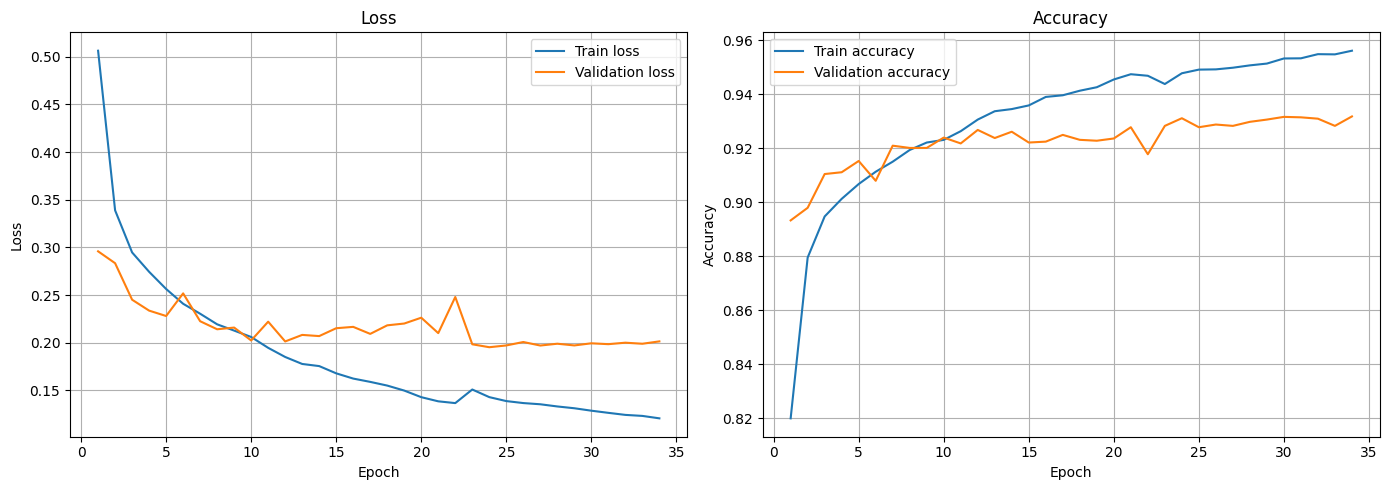

In [35]:
import matplotlib.pyplot as plt


epochs = history["epoch"]

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5),
)

# График ошибки
axes[0].plot(
    epochs,
    history["train_loss"],
    label="Train loss",
)

axes[0].plot(
    epochs,
    history["validation_loss"],
    label="Validation loss",
)

axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid()


# График accuracy
axes[1].plot(
    epochs,
    history["train_accuracy"],
    label="Train accuracy",
)

axes[1].plot(
    epochs,
    history["validation_accuracy"],
    label="Validation accuracy",
)

axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

In [36]:
best_index = history["validation_loss"].index(
    min(history["validation_loss"])
)

best_epoch = history["epoch"][best_index]
best_validation_loss = (
    history["validation_loss"][best_index]
)
best_validation_accuracy = (
    history["validation_accuracy"][best_index]
)
best_stage = history["stage"][best_index]

print("Лучшая эпоха по Validation Loss:", best_epoch)
print("Лучший этап:", best_stage)
print("Минимальный Validation Loss:", best_validation_loss)
print("Validation Accuracy на лучшей эпохе:", best_validation_accuracy)
print("В процентах:", best_validation_accuracy * 100)

Лучшая эпоха по Validation Loss: 24
Лучший этап: 2
Минимальный Validation Loss: 0.19537509195009867
Validation Accuracy на лучшей эпохе: 0.9311666666666667
В процентах: 93.11666666666667


In [37]:
#Проверка содержимого checkpoint
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
)
print(checkpoint.keys())

dict_keys(['epoch', 'stage', 'model_state_dict', 'optimizer_state_dict', 'validation_loss', 'validation_accuracy', 'best_validation_loss', 'history', 'seed', 'normalization', 'architecture', 'training', 'dataset_sizes'])


### 14. Расчёт метрик на test

In [38]:
from torch.utils.data import DataLoader

#Создание test_loader
test_loader = DataLoader(
    test_dataset,
    batch_size=training_config["batch_size"],
    shuffle=False,
    num_workers=0,
)

In [39]:
#Загрузка общей модели
import torch
from src.model import FashionCNN


checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
)

saved_training_config = checkpoint.get(
    "training",
    training_config,
)

best_model = FashionCNN(
    dropout=saved_training_config["dropout"]
).to(device)

best_model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_model.eval()

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [40]:
print("Эпоха модели:", checkpoint["epoch"])
print(
    "Validation accuracy:",
    checkpoint["validation_accuracy"],
)

Эпоха модели: 24
Validation accuracy: 0.9311666666666667


In [41]:
# Предсказания на train, validation и test
import csv
import json
from pathlib import Path

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
)


train_eval_loader = DataLoader(
    train_dataset,
    batch_size=training_config["batch_size"],
    shuffle=False,
    num_workers=0,
)


def collect_predictions(
    model,
    data_loader,
    device,
):
    all_labels = []
    all_predictions = []

    model.eval()

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)

            logits = model(images)
            predictions = logits.argmax(dim=1)

            all_labels.append(labels.cpu())
            all_predictions.append(predictions.cpu())

    return (
        torch.cat(all_labels).numpy(),
        torch.cat(all_predictions).numpy(),
    )


train_y_true, train_y_pred = collect_predictions(
    model=best_model,
    data_loader=train_eval_loader,
    device=device,
)

validation_y_true, validation_y_pred = collect_predictions(
    model=best_model,
    data_loader=validation_loader,
    device=device,
)

test_y_true, test_y_pred = collect_predictions(
    model=best_model,
    data_loader=test_loader,
    device=device,
)

# Эти имена используются в следующих разделах
y_true = test_y_true
y_pred = test_y_pred

class_ids = np.arange(len(CLASS_NAMES))


def calculate_per_class_metrics(
    y_true,
    y_pred,
):
    matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=class_ids,
    )

    total_samples = int(matrix.sum())
    rows = []

    for class_id, class_name in enumerate(CLASS_NAMES):
        tp = int(matrix[class_id, class_id])
        fn = int(matrix[class_id, :].sum() - tp)
        fp = int(matrix[:, class_id].sum() - tp)
        tn = int(total_samples - tp - fn - fp)
        support = tp + fn

        recall = tp / support if support > 0 else 0.0
        accuracy = (tp + tn) / total_samples

        rows.append({
            "class_id": class_id,
            "class_name": class_name,
            "recall": float(recall),
            "accuracy": float(accuracy),
            "support": support,
            "true_positive": tp,
            "false_positive": fp,
            "false_negative": fn,
        })

    return matrix, rows


def save_per_class_metrics(rows, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    fieldnames = [
        "class_id",
        "class_name",
        "recall",
        "accuracy",
        "support",
        "true_positive",
        "false_positive",
        "false_negative",
    ]

    with path.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)


train_confusion, train_rows = calculate_per_class_metrics(
    train_y_true, train_y_pred
)
validation_confusion, validation_rows = calculate_per_class_metrics(
    validation_y_true, validation_y_pred
)
test_confusion, test_rows = calculate_per_class_metrics(
    test_y_true, test_y_pred
)

# Матрица test используется в разделе 15
confusion = test_confusion

metrics_dir = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "baseline"
    / "metrics"
)
metrics_dir.mkdir(parents=True, exist_ok=True)

save_per_class_metrics(
    train_rows,
    metrics_dir / "train_per_class_metrics.csv",
)
save_per_class_metrics(
    validation_rows,
    metrics_dir / "validation_per_class_metrics.csv",
)
save_per_class_metrics(
    test_rows,
    metrics_dir / "test_per_class_metrics.csv",
)

overall_accuracy = accuracy_score(test_y_true, test_y_pred)
macro_f1 = f1_score(
    test_y_true,
    test_y_pred,
    average="macro",
    zero_division=0,
)

test_metrics = {
    "experiment": "Full F baseline",
    "train_size": len(train_dataset),
    "validation_size": len(validation_dataset),
    "test_size": len(test_dataset),
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "checkpoint_stage": int(checkpoint["stage"]),
    "validation_loss": float(checkpoint["validation_loss"]),
    "validation_accuracy": float(checkpoint["validation_accuracy"]),
    "test_accuracy": float(overall_accuracy),
    "macro_f1": float(macro_f1),
    "seed": int(SEED),
}

(metrics_dir / "test_metrics.json").write_text(
    json.dumps(test_metrics, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("Full F метрики сохранены.")
print("Test accuracy:", overall_accuracy)
print("Macro-F1:", macro_f1)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint stage:", checkpoint["stage"])
print("Validation Loss:", checkpoint["validation_loss"])

Full F метрики сохранены.
Test accuracy: 0.92
Macro-F1: 0.9197469417870059
Checkpoint epoch: 24
Checkpoint stage: 2
Validation Loss: 0.19537509195009867


In [42]:
# Общие метрики рассчитаны и сохранены в предыдущей ячейке.
print("Test accuracy:", overall_accuracy)
print("Macro-F1:", macro_f1)

Test accuracy: 0.92
Macro-F1: 0.9197469417870059


In [43]:
# Recall и Accuracy по классам рассчитаны выше.
for row in test_rows:
    print(
        f"{row['class_name']}: "
        f"Recall={row['recall']:.4f}, "
        f"Accuracy={row['accuracy']:.4f}"
    )

T-shirt/top: Recall=0.8810, Accuracy=0.9737
Trouser: Recall=0.9850, Accuracy=0.9975
Pullover: Recall=0.8680, Accuracy=0.9755
Dress: Recall=0.9210, Accuracy=0.9834
Coat: Recall=0.8910, Accuracy=0.9749
Sandal: Recall=0.9800, Accuracy=0.9967
Shirt: Recall=0.7460, Accuracy=0.9538
Sneaker: Recall=0.9800, Accuracy=0.9937
Bag: Recall=0.9830, Accuracy=0.9965
Ankle boot: Recall=0.9650, Accuracy=0.9943


In [44]:
# Общая метрика уже сохранена в предыдущей ячейке.
print("Файл test_metrics.json сохранён.")

Файл test_metrics.json сохранён.


In [45]:
# Отдельные CSV по train, validation и test уже сохранены выше.
print("Файлы метрик по классам сохранены.")

Файлы метрик по классам сохранены.


### 15. Построение матрицы ошибок

In [46]:
from sklearn.metrics import confusion_matrix


class_ids = np.arange(len(CLASS_NAMES))

confusion = confusion_matrix(
    y_true,
    y_pred,
    labels=class_ids,
)

print("Размер матрицы:", confusion.shape)
print(confusion)

Размер матрицы: (10, 10)
[[881   0  11  17   4   1  84   0   2   0]
 [  0 985   1   9   1   0   3   0   1   0]
 [ 20   1 868   6  52   0  52   0   1   0]
 [ 14   4  10 921  21   0  29   0   1   0]
 [  2   0  42  25 891   0  38   0   2   0]
 [  0   0   0   0   0 980   0  13   0   7]
 [104   2  48  28  62   0 746   0  10   0]
 [  0   0   0   0   0   5   0 980   0  15]
 [  4   3   1   2   2   2   2   1 983   0]
 [  0   0   0   0   0   5   0  29   1 965]]


In [47]:
#Сохранение матрицы в CSV
import csv


metrics_dir = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "baseline"
    / "metrics"
)

metrics_dir.mkdir(
    parents=True,
    exist_ok=True,
)

confusion_csv_path = (
    metrics_dir
    / "confusion_matrix.csv"
)

with confusion_csv_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:

    writer = csv.writer(csv_file)

    writer.writerow(
        ["true_class"] + list(CLASS_NAMES)
    )

    for class_name, row in zip(
        CLASS_NAMES,
        confusion,
    ):
        writer.writerow(
            [class_name] + row.tolist()
        )

print(
    "CSV сохранён в:",
    confusion_csv_path,
)

CSV сохранён в: d:\Учеба\fashion-mnist-cnn-experiments\experiments\fashion_mnist\baseline\metrics\confusion_matrix.csv


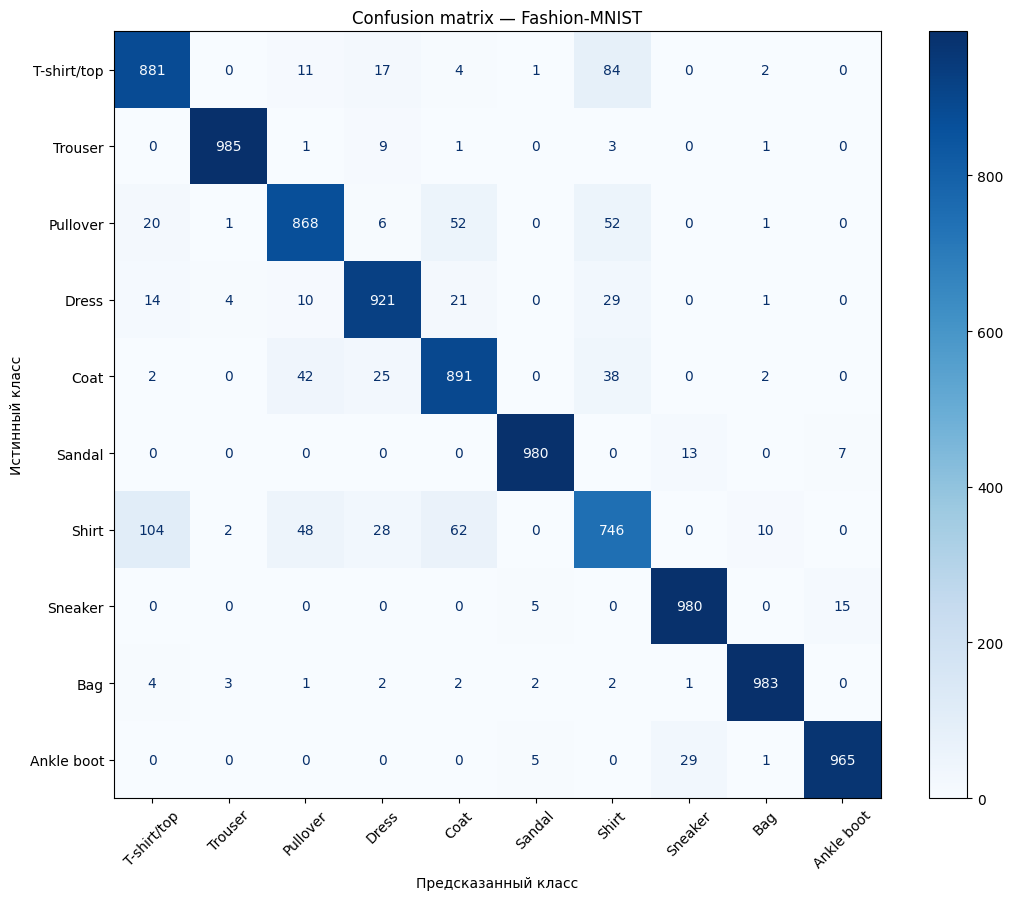

Изображение сохранено в: d:\Учеба\fashion-mnist-cnn-experiments\experiments\fashion_mnist\baseline\figures\confusion_matrix.png


In [48]:
from sklearn.metrics import ConfusionMatrixDisplay


figures_dir = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "baseline"
    / "figures"
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True,
)

confusion_png_path = (
    figures_dir
    / "confusion_matrix.png"
)

fig, ax = plt.subplots(
    figsize=(11, 9),
)

display = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=CLASS_NAMES,
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=True,
)

ax.set_title(
    "Confusion matrix — Fashion-MNIST"
)

ax.set_xlabel(
    "Предсказанный класс"
)

ax.set_ylabel(
    "Истинный класс"
)

fig.tight_layout()

fig.savefig(
    confusion_png_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print(
    "Изображение сохранено в:",
    confusion_png_path,
)

In [49]:
#Какой класс распознаётся лучше всего
class_accuracies = []

for class_id, class_name in enumerate(CLASS_NAMES):
    total_samples = confusion[class_id].sum()
    correct_predictions = confusion[
        class_id,
        class_id,
    ]

    accuracy = (
        correct_predictions / total_samples
    )

    class_accuracies.append(accuracy)

best_class_id = int(
    np.argmax(class_accuracies)
)

worst_class_id = int(
    np.argmin(class_accuracies)
)

print(
    "Лучше всего распознаётся:",
    CLASS_NAMES[best_class_id],
    class_accuracies[best_class_id],
)

print(
    "Хуже всего распознаётся:",
    CLASS_NAMES[worst_class_id],
    class_accuracies[worst_class_id],
)

Лучше всего распознаётся: Trouser 0.985
Хуже всего распознаётся: Shirt 0.746


In [50]:
#какие классы чаще всего путаются
pair_errors = []

num_classes = len(CLASS_NAMES)

for first_class in range(num_classes):
    for second_class in range(
        first_class + 1,
        num_classes,
    ):
        errors = (
            confusion[first_class, second_class]
            + confusion[second_class, first_class]
        )

        pair_errors.append(
            {
                "first_class": first_class,
                "second_class": second_class,
                "errors": int(errors),
            }
        )

most_confused_pair = max(
    pair_errors,
    key=lambda item: item["errors"],
)

first_class = most_confused_pair["first_class"]
second_class = most_confused_pair["second_class"]

print(
    "Чаще всего путаются:",
    CLASS_NAMES[first_class],
    "и",
    CLASS_NAMES[second_class],
)

print(
    "Количество ошибок в обе стороны:",
    most_confused_pair["errors"],
)

Чаще всего путаются: T-shirt/top и Shirt
Количество ошибок в обе стороны: 188


In [51]:
#Направление основной ошибки для каждого класса
for class_id, class_name in enumerate(CLASS_NAMES):
    errors = confusion[class_id].copy()

    # Убираем правильные предсказания
    errors[class_id] = 0

    most_common_wrong_class = int(
        np.argmax(errors)
    )

    print(
        f"{class_name} чаще всего принимает "
        f"за {CLASS_NAMES[most_common_wrong_class]}: "
        f"{errors[most_common_wrong_class]} раз"
    )

T-shirt/top чаще всего принимает за Shirt: 84 раз
Trouser чаще всего принимает за Dress: 9 раз
Pullover чаще всего принимает за Coat: 52 раз
Dress чаще всего принимает за Shirt: 29 раз
Coat чаще всего принимает за Pullover: 42 раз
Sandal чаще всего принимает за Sneaker: 13 раз
Shirt чаще всего принимает за T-shirt/top: 104 раз
Sneaker чаще всего принимает за Ankle boot: 15 раз
Bag чаще всего принимает за T-shirt/top: 4 раз
Ankle boot чаще всего принимает за Sneaker: 29 раз


In [52]:
#Проверка симметричности ошибок
is_symmetric = np.array_equal(
    confusion,
    confusion.T,
)

print(
    "Матрица полностью симметрична:",
    is_symmetric,
)

Матрица полностью симметрична: False


In [53]:
max_difference = 0
most_asymmetric_pair = None

for first_class in range(num_classes):
    for second_class in range(
        first_class + 1,
        num_classes,
    ):
        difference = abs(
            confusion[first_class, second_class]
            - confusion[second_class, first_class]
        )

        if difference > max_difference:
            max_difference = difference
            most_asymmetric_pair = (
                first_class,
                second_class,
            )

first_class, second_class = most_asymmetric_pair

print(
    "Наиболее несимметричная пара:",
    CLASS_NAMES[first_class],
    "и",
    CLASS_NAMES[second_class],
)

print(
    f"{CLASS_NAMES[first_class]} → "
    f"{CLASS_NAMES[second_class]}:",
    confusion[first_class, second_class],
)

print(
    f"{CLASS_NAMES[second_class]} → "
    f"{CLASS_NAMES[first_class]}:",
    confusion[second_class, first_class],
)

Наиболее несимметричная пара: Coat и Shirt
Coat → Shirt: 38
Shirt → Coat: 62


Для полной выборки Fashion-MNIST используется CNN с фиксированной архитектурой, оптимизатор Adam и функция потерь CrossEntropyLoss. Обучение проводится в два этапа: сначала с исходным learning rate, затем с уменьшенным в 10 раз. На каждом этапе используется остановка по отсутствию улучшения Validation Loss в течение 10 эпох.

Checkpoint полной модели выбирается по минимальному Validation Loss. Актуальные значения Validation Loss, Validation Accuracy, Test Accuracy, Macro-F1 и метрики по классам сохраняются в папке experiments/fashion_mnist/baseline.

Эта модель используется как базовая точка для дальнейшего сравнения с F-A и моделями, обученными на дополненных наборах данных.

### 16. Разделение train на F-A и F-B

In [54]:
from sklearn.model_selection import train_test_split


fa_experiment_root = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "fa_fb"
)

fa_experiment_root.mkdir(
    parents=True,
    exist_ok=True,
)

# Метки исходной полной обучающей выборки
full_targets = (
    full_train_dataset.targets
    .cpu()
    .numpy()
)

# F-A и F-B делим только внутри train
source_train_indices = np.asarray(
    train_indices,
    dtype=np.int64,
)

source_train_targets = full_targets[
    source_train_indices
]

fa_indices, fb_indices = train_test_split(
    source_train_indices,
    train_size=0.20,
    test_size=0.80,
    stratify=source_train_targets,
    random_state=SEED,
)

fa_indices = np.asarray(
    fa_indices,
    dtype=np.int64,
)

fb_indices = np.asarray(
    fb_indices,
    dtype=np.int64,
)

In [55]:
#Проверка размеров и пересечений
assert len(fa_indices) == 10800
assert len(fb_indices) == 43200

assert len(
    np.intersect1d(
        fa_indices,
        fb_indices,
    )
) == 0

combined_indices = np.concatenate(
    [fa_indices, fb_indices]
)

assert set(combined_indices) == set(
    source_train_indices
)

print("Размер F-A:", len(fa_indices))
print("Размер F-B:", len(fb_indices))
print("Размер validation:", len(validation_indices))
print("Размер test:", len(test_dataset))
print("F-A и F-B не пересекаются")

Размер F-A: 10800
Размер F-B: 43200
Размер validation: 6000
Размер test: 10000
F-A и F-B не пересекаются


In [56]:
#Проверка распределения классов
fa_class_counts = np.bincount(
    full_targets[fa_indices],
    minlength=len(CLASS_NAMES),
)

fb_class_counts = np.bincount(
    full_targets[fb_indices],
    minlength=len(CLASS_NAMES),
)

for class_id, class_name in enumerate(CLASS_NAMES):
    print(
        f"{class_id}: {class_name:12s} | "
        f"F-A = {fa_class_counts[class_id]:4d} | "
        f"F-B = {fb_class_counts[class_id]:4d}"
    )

0: T-shirt/top  | F-A = 1080 | F-B = 4320
1: Trouser      | F-A = 1080 | F-B = 4320
2: Pullover     | F-A = 1080 | F-B = 4320
3: Dress        | F-A = 1080 | F-B = 4320
4: Coat         | F-A = 1080 | F-B = 4320
5: Sandal       | F-A = 1080 | F-B = 4320
6: Shirt        | F-A = 1080 | F-B = 4320
7: Sneaker      | F-A = 1080 | F-B = 4320
8: Bag          | F-A = 1080 | F-B = 4320
9: Ankle boot   | F-A = 1080 | F-B = 4320


In [57]:
#Сохраним индексы
split_indices_path = (
    fa_experiment_root
    / "split_indices.npz"
)

np.savez(
    split_indices_path,
    fa_indices=fa_indices,
    fb_indices=fb_indices,
    validation_indices=validation_indices,
    test_indices=np.arange(
        len(test_dataset)
    ),
)

In [58]:
split_metadata = {
    "seed": int(SEED),
    "source_split": "original train split",
    "source_train_size": int(
        len(source_train_indices)
    ),
    "fa_size": int(len(fa_indices)),
    "fb_size": int(len(fb_indices)),
    "fa_fraction": 0.20,
    "fb_fraction": 0.80,
    "validation_size": int(
        len(validation_indices)
    ),
    "test_size": int(len(test_dataset)),
    "stratified": True,
}

split_metadata_path = (
    fa_experiment_root
    / "split_metadata.json"
)

split_metadata_path.write_text(
    json.dumps(
        split_metadata,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    "Индексы сохранены в:",
    split_indices_path,
)

Индексы сохранены в: d:\Учеба\fashion-mnist-cnn-experiments\experiments\fashion_mnist\fa_fb\split_indices.npz


### 17. Подготовка датасетов для F-A

In [59]:
#Для нового эксперимента посчитаем нормализацию только по F-A
from copy import copy
from torch.utils.data import Subset


fa_mean, fa_std = calculate_train_mean_std(
    full_train_dataset=full_train_dataset,
    train_indices=fa_indices,
)

print("Среднее F-A:", fa_mean)
print("Стандартное отклонение F-A:", fa_std)

Среднее F-A: 0.28624583872177345
Стандартное отклонение F-A: 0.3536617571752594


In [60]:
#Создадим отдельные копии датасетов, чтобы не менять предыдущий эксперимент
fa_transform = create_normalized_transform(
    mean=fa_mean,
    std=fa_std,
)

fa_parent_dataset = copy(
    full_train_dataset
)

fa_parent_dataset.transform = fa_transform

fa_test_parent_dataset = copy(
    test_dataset
)

fa_test_parent_dataset.transform = fa_transform

In [61]:
#Создадим F-A, F-B и validation
fa_dataset = Subset(
    fa_parent_dataset,
    fa_indices.tolist(),
)

fb_dataset = Subset(
    fa_parent_dataset,
    fb_indices.tolist(),
)

fa_validation_dataset = Subset(
    fa_parent_dataset,
    validation_indices.tolist(),
)

fa_test_dataset = fa_test_parent_dataset

In [62]:
#Проверим размеры
print("F-A:", len(fa_dataset))
print("F-B:", len(fb_dataset))
print(
    "Validation:",
    len(fa_validation_dataset),
)
print("Test:", len(fa_test_dataset))

F-A: 10800
F-B: 43200
Validation: 6000
Test: 10000


### 18. Обучение CNN только на F-A

In [63]:
from torch.utils.data import DataLoader


fa_train_loader = DataLoader(
    fa_dataset,
    batch_size=training_config["batch_size"],
    shuffle=True,
    num_workers=0,
)

fa_validation_loader = DataLoader(
    fa_validation_dataset,
    batch_size=training_config["batch_size"],
    shuffle=False,
    num_workers=0,
)

fa_test_loader = DataLoader(
    fa_test_dataset,
    batch_size=training_config["batch_size"],
    shuffle=False,
    num_workers=0,
)

print(
    "Train batches:",
    len(fa_train_loader),
)

print(
    "Validation batches:",
    len(fa_validation_loader),
)

print(
    "Test batches:",
    len(fa_test_loader),
)

Train batches: 85
Validation batches: 47
Test batches: 79


In [64]:
#Создадим отдельную конфигурацию
fa_training_config = {
    **training_config,
    "train_split": "F-A",
    "train_size": len(fa_dataset),
    "validation_size": len(
        fa_validation_dataset
    ),
    "test_size": len(fa_test_dataset),
}

In [65]:
#Пути для нового эксперимента
fa_baseline_root = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "fa_baseline"
)

fa_checkpoint_path = (
    fa_baseline_root
    / "checkpoints"
    / "best_model.pt"
)

fa_history_path = (
    fa_baseline_root
    / "history.json"
)

In [66]:
#Метаданные нового checkpoint
fa_normalization_config = {
    "mean": float(fa_mean),
    "std": float(fa_std),
    "calculated_from": "F-A only",
}

fa_checkpoint_metadata = {
    "experiment": "F-A baseline",
    "seed": int(SEED),
    "normalization": fa_normalization_config,
    "architecture": architecture_config,
    "training": fa_training_config,
    "dataset_sizes": {
        "train": len(fa_dataset),
        "validation": len(
            fa_validation_dataset
        ),
        "test": len(fa_test_dataset),
        "fb_reserved": len(fb_dataset),
    },
}

In [67]:
import importlib

import src.train as train_module

# Перечитываем изменённый файл src/train.py
importlib.reload(train_module)

from src.train import fit_two_stage


# Фиксируем seed для воспроизводимости
set_seed(SEED)


# Создаём модель F-A с нуля
fa_model = FashionCNN(
    dropout=fa_training_config["dropout"]
).to(device)


fa_criterion = nn.CrossEntropyLoss()


fa_optimizer = torch.optim.Adam(
    fa_model.parameters(),
    lr=fa_training_config[
        "learning_rate"
    ],
    weight_decay=fa_training_config[
        "weight_decay"
    ],
)


In [68]:
# Двухэтапное обучение F-A
fa_history = fit_two_stage(
    model=fa_model,
    train_loader=fa_train_loader,
    validation_loader=fa_validation_loader,
    criterion=fa_criterion,
    optimizer=fa_optimizer,
    device=device,
    epochs=fa_training_config[
        "epochs"
    ],
    patience=fa_training_config[
        "early_stopping_patience"
    ],
    min_delta=fa_training_config[
        "min_delta"
    ],
    lr_factor=fa_training_config[
        "learning_rate_factor"
    ],
    checkpoint_path=fa_checkpoint_path,
    history_path=fa_history_path,
    checkpoint_metadata=fa_checkpoint_metadata,
)

Stage 1 | Epoch 001 | lr: 0.001000 | train loss: 0.8134 | train accuracy: 0.7191 | validation loss: 0.4715 | validation accuracy: 0.8378
Stage 1 | Epoch 002 | lr: 0.001000 | train loss: 0.4905 | train accuracy: 0.8287 | validation loss: 0.3942 | validation accuracy: 0.8637
Stage 1 | Epoch 003 | lr: 0.001000 | train loss: 0.4075 | train accuracy: 0.8604 | validation loss: 0.3636 | validation accuracy: 0.8672
Stage 1 | Epoch 004 | lr: 0.001000 | train loss: 0.3663 | train accuracy: 0.8704 | validation loss: 0.3424 | validation accuracy: 0.8743
Stage 1 | Epoch 005 | lr: 0.001000 | train loss: 0.3271 | train accuracy: 0.8849 | validation loss: 0.3227 | validation accuracy: 0.8855
Stage 1 | Epoch 006 | lr: 0.001000 | train loss: 0.2972 | train accuracy: 0.8932 | validation loss: 0.3065 | validation accuracy: 0.8892
Stage 1 | Epoch 007 | lr: 0.001000 | train loss: 0.2785 | train accuracy: 0.9015 | validation loss: 0.2939 | validation accuracy: 0.8955
Stage 1 | Epoch 008 | lr: 0.001000 | trai

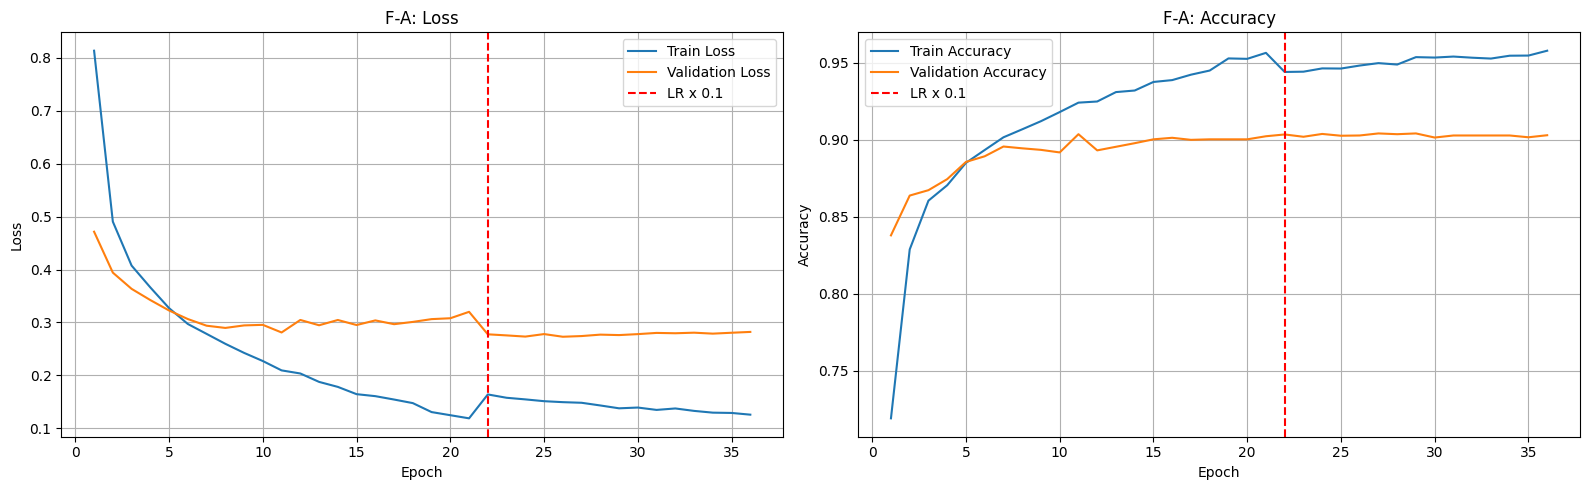

График сохранён: d:\Учеба\fashion-mnist-cnn-experiments\experiments\fashion_mnist\fa_baseline\figures\training_curves.png


In [69]:
import matplotlib.pyplot as plt


fa_epochs = fa_history["epoch"]
fa_stages = fa_history["stage"]


fa_training_curves_path = (
    fa_baseline_root
    / "figures"
    / "training_curves.png"
)

fa_training_curves_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)


fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 5),
)


# График Loss
axes[0].plot(
    fa_epochs,
    fa_history["train_loss"],
    label="Train Loss",
)

axes[0].plot(
    fa_epochs,
    fa_history["validation_loss"],
    label="Validation Loss",
)


# Находим начало второго этапа
stage_2_epochs = [
    epoch
    for epoch, stage in zip(
        fa_epochs,
        fa_stages,
    )
    if stage == 2
]


if len(stage_2_epochs) > 0:
    stage_2_start = stage_2_epochs[0]

    axes[0].axvline(
        stage_2_start,
        color="red",
        linestyle="--",
        label="LR x 0.1",
    )


axes[0].set_title(
    "F-A: Loss"
)

axes[0].set_xlabel(
    "Epoch"
)

axes[0].set_ylabel(
    "Loss"
)

axes[0].legend()
axes[0].grid()


# График Accuracy
axes[1].plot(
    fa_epochs,
    fa_history["train_accuracy"],
    label="Train Accuracy",
)

axes[1].plot(
    fa_epochs,
    fa_history["validation_accuracy"],
    label="Validation Accuracy",
)

if len(stage_2_epochs) > 0:
    axes[1].axvline(
        stage_2_start,
        color="red",
        linestyle="--",
        label="LR x 0.1",
    )


axes[1].set_title(
    "F-A: Accuracy"
)

axes[1].set_xlabel(
    "Epoch"
)

axes[1].set_ylabel(
    "Accuracy"
)

axes[1].legend()
axes[1].grid()


plt.tight_layout()


fig.savefig(
    fa_training_curves_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


print(
    "График сохранён:",
    fa_training_curves_path,
)

### 19. Итоговая оценка F-A модели

In [70]:
import csv
import json
from pathlib import Path

import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
)


# Загружаем лучший checkpoint
fa_checkpoint = torch.load(
    fa_checkpoint_path,
    map_location=device,
)


# Создаём модель для оценки
fa_best_model = FashionCNN(
    dropout=fa_training_config["dropout"]
).to(device)


fa_best_model.load_state_dict(
    fa_checkpoint[
        "model_state_dict"
    ]
)

fa_best_model.eval()


# Для расчёта метрик train
# используем shuffle=False
fa_train_eval_loader = DataLoader(
    fa_dataset,
    batch_size=fa_training_config[
        "batch_size"
    ],
    shuffle=False,
    num_workers=0,
)


def collect_predictions(
    model,
    data_loader,
    device,
):
    all_labels = []
    all_predictions = []

    model.eval()

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)

            logits = model(images)

            predictions = logits.argmax(
                dim=1
            )

            all_labels.append(
                labels.cpu()
            )

            all_predictions.append(
                predictions.cpu()
            )

    y_true = torch.cat(
        all_labels
    ).numpy()

    y_pred = torch.cat(
        all_predictions
    ).numpy()

    return y_true, y_pred


# Предсказания на трёх выборках
fa_train_y_true, fa_train_y_pred = (
    collect_predictions(
        model=fa_best_model,
        data_loader=fa_train_eval_loader,
        device=device,
    )
)


fa_validation_y_true, fa_validation_y_pred = (
    collect_predictions(
        model=fa_best_model,
        data_loader=fa_validation_loader,
        device=device,
    )
)


fa_test_y_true, fa_test_y_pred = (
    collect_predictions(
        model=fa_best_model,
        data_loader=fa_test_loader,
        device=device,
    )
)


# Оставляем старые имена переменных,
# чтобы последующие ячейки не сломались
fa_y_true = fa_test_y_true
fa_y_pred = fa_test_y_pred


def calculate_per_class_metrics(
    y_true,
    y_pred,
    class_names,
):
    confusion = confusion_matrix(
        y_true,
        y_pred,
        labels=list(
            range(len(class_names))
        ),
    )

    total_samples = int(
        confusion.sum()
    )

    rows = []

    for class_id, class_name in enumerate(
        class_names
    ):
        true_positive = int(
            confusion[
                class_id,
                class_id,
            ]
        )

        false_negative = int(
            confusion[class_id, :].sum()
            - true_positive
        )

        false_positive = int(
            confusion[:, class_id].sum()
            - true_positive
        )

        true_negative = int(
            total_samples
            - true_positive
            - false_negative
            - false_positive
        )

        support = (
            true_positive
            + false_negative
        )

        recall = (
            true_positive / support
            if support > 0
            else 0.0
        )

        accuracy = (
            (true_positive + true_negative)
            / total_samples
            if total_samples > 0
            else 0.0
        )

        rows.append(
            {
                "class_id": class_id,
                "class_name": class_name,
                "recall": float(recall),
                "accuracy": float(accuracy),
                "support": int(support),
                "true_positive": true_positive,
                "false_positive": false_positive,
                "false_negative": false_negative,
            }
        )

    return confusion, rows


def save_per_class_metrics(
    rows,
    output_path,
):
    output_path = Path(output_path)
    output_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    fieldnames = [
        "class_id",
        "class_name",
        "recall",
        "accuracy",
        "support",
        "true_positive",
        "false_positive",
        "false_negative",
    ]

    with output_path.open(
        "w",
        newline="",
        encoding="utf-8",
    ) as csv_file:
        writer = csv.DictWriter(
            csv_file,
            fieldnames=fieldnames,
        )

        writer.writeheader()
        writer.writerows(rows)


fa_metrics_dir = (
    fa_baseline_root
    / "metrics"
)

fa_metrics_dir.mkdir(
    parents=True,
    exist_ok=True,
)


# Train
fa_train_confusion, fa_train_rows = (
    calculate_per_class_metrics(
        fa_train_y_true,
        fa_train_y_pred,
        CLASS_NAMES,
    )
)


save_per_class_metrics(
    fa_train_rows,
    fa_metrics_dir
    / "train_per_class_metrics.csv",
)


# Validation
fa_validation_confusion, fa_validation_rows = (
    calculate_per_class_metrics(
        fa_validation_y_true,
        fa_validation_y_pred,
        CLASS_NAMES,
    )
)


save_per_class_metrics(
    fa_validation_rows,
    fa_metrics_dir
    / "validation_per_class_metrics.csv",
)


# Test
fa_test_confusion, fa_test_rows = (
    calculate_per_class_metrics(
        fa_test_y_true,
        fa_test_y_pred,
        CLASS_NAMES,
    )
)


save_per_class_metrics(
    fa_test_rows,
    fa_metrics_dir
    / "test_per_class_metrics.csv",
)


# Общие test-метрики
fa_test_accuracy = accuracy_score(
    fa_test_y_true,
    fa_test_y_pred,
)


fa_macro_f1 = f1_score(
    fa_test_y_true,
    fa_test_y_pred,
    average="macro",
    zero_division=0,
)


fa_test_metrics = {
    "experiment": "F-A baseline",
    "train_size": len(fa_dataset),
    "validation_size": len(
        fa_validation_dataset
    ),
    "test_size": len(
        fa_test_dataset
    ),
    "checkpoint_epoch": int(
        fa_checkpoint["epoch"]
    ),
    "checkpoint_stage": int(
        fa_checkpoint["stage"]
    ),
    "validation_loss": float(
        fa_checkpoint["validation_loss"]
    ),
    "validation_accuracy": float(
        fa_checkpoint["validation_accuracy"]
    ),
    "test_accuracy": float(
        fa_test_accuracy
    ),
    "macro_f1": float(
        fa_macro_f1
    ),
    "seed": int(SEED),
}


fa_test_metrics_path = (
    fa_metrics_dir
    / "test_metrics.json"
)


fa_test_metrics_path.write_text(
    json.dumps(
        fa_test_metrics,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


# Сохраняем test confusion matrix
fa_confusion_csv_path = (
    fa_metrics_dir
    / "confusion_matrix.csv"
)


with fa_confusion_csv_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:
    writer = csv.writer(csv_file)

    writer.writerow(
        ["true_class"]
        + list(CLASS_NAMES)
    )

    for class_name, row in zip(
        CLASS_NAMES,
        fa_test_confusion,
    ):
        writer.writerow(
            [class_name]
            + row.tolist()
        )


print("F-A метрики сохранены.")
print()
print("Test accuracy:", fa_test_accuracy)
print("Macro-F1:", fa_macro_f1)
print()
print(
    "Checkpoint epoch:",
    fa_checkpoint["epoch"],
)
print(
    "Checkpoint stage:",
    fa_checkpoint["stage"],
)
print(
    "Validation Loss:",
    fa_checkpoint["validation_loss"],
)

F-A метрики сохранены.

Test accuracy: 0.893
Macro-F1: 0.892674991620833

Checkpoint epoch: 26
Checkpoint stage: 2
Validation Loss: 0.27308361188570657


F-A используется как базовая модель для эксперимента с ограниченным количеством реальных обучающих данных. Исходная обучающая выборка разделена на F-A и F-B стратифицированно, с фиксированным seed. F-A содержит 10 800 изображений, а F-B используется как резервный набор. Validation и test-выборки остаются отдельными.

Модель F-A обучается по той же двухэтапной схеме, что и полная модель: с early stopping по Validation Loss и уменьшением learning rate в 10 раз после первого этапа. Checkpoint выбирается по минимальному Validation Loss.

Актуальные результаты F-A сохраняются в папке experiments/fashion_mnist/fa_baseline и используются как базовая точка перед реализацией стратегий добавления изображений.

На данном этапе были обучены и оценены две CNN-модели: модель на полной обучающей выборке F и модель на сокращённой выборке F-A. Для обеих моделей использовались одинаковая архитектура, двухэтапная схема обучения, early stopping по Validation Loss и уменьшение learning rate в 10 раз на втором этапе.

Модель F показала Test Accuracy 0,9200 и Macro-F1 0,9197. Для модели F-A Test Accuracy составила 0,8930, а Macro-F1 — 0,8927. Таким образом, сокращение обучающей выборки привело к снижению Accuracy примерно на 2,70 процентного пункта, а Macro-F1 — примерно на 2,71 процентного пункта.

Наибольшие трудности у обеих моделей возникают при распознавании класса Shirt. Суммарное количество ошибок между классами T-shirt/top и Shirt составило 188 для модели F и 223 для модели F-A. Это подтверждает, что увеличение объёма обучающих данных улучшает качество классификации и уменьшает количество ошибок между наиболее сложными классами.

Полученные модели F и F-A зафиксированы как базовые точки для дальнейшего эксперимента со стратегиями отбора и добавления новых изображений из F-B.

### 20. Настройки проверки устойчивости

In [71]:
# 20. Проверка устойчивости ошибок
# Модели с разными случайными инициализациями

from pathlib import Path
import csv
import json

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader

from src.model import FashionCNN
from src.train import fit_two_stage


# Количество независимых запусков CNN
STABILITY_RUNS = 5

# Разные seed для разных запусков
STABILITY_SEEDS = [
    SEED + run_id
    for run_id in range(STABILITY_RUNS)
]

# Контрольная выборка.
# Test здесь не используется.
CONTROL_DATASET = fa_validation_dataset
CONTROL_ORIGINAL_INDICES = np.asarray(
    validation_indices,
    dtype=np.int64,
)

CONTROL_DATASET_NAME = "F-A validation"


# Папка для результатов
stability_root = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "model_stability"
)

stability_root.mkdir(
    parents=True,
    exist_ok=True,
)


assert len(CONTROL_DATASET) == len(
    CONTROL_ORIGINAL_INDICES
)

print(
    "Контрольная выборка:",
    CONTROL_DATASET_NAME,
)

print(
    "Размер контрольной выборки:",
    len(CONTROL_DATASET),
)

print(
    "Количество запусков CNN:",
    STABILITY_RUNS,
)

print(
    "Seed запусков:",
    STABILITY_SEEDS,
)

print(
    "Устройство:",
    device,
)

Контрольная выборка: F-A validation
Размер контрольной выборки: 6000
Количество запусков CNN: 5
Seed запусков: [42, 43, 44, 45, 46]
Устройство: cuda


### 21. Вспомогательные функции

In [72]:
def create_stability_loader(
    dataset,
    shuffle,
    seed=None,
):
    """
    Создаёт DataLoader.

    Для train используется отдельный generator
    каждого запуска, чтобы порядок батчей также
    зависел от seed.
    """

    generator = torch.Generator()

    if seed is not None:
        generator.manual_seed(int(seed))

    return DataLoader(
        dataset,
        batch_size=fa_training_config["batch_size"],
        shuffle=shuffle,
        num_workers=0,
        generator=generator,
    )


def collect_control_predictions(
    model,
    data_loader,
    device,
):
    """
    Получает истинные классы и предсказания
    модели на контрольной выборке.
    """

    all_labels = []
    all_predictions = []

    model.eval()

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)

            logits = model(images)

            predictions = logits.argmax(
                dim=1
            )

            all_labels.append(
                labels.detach()
                .cpu()
                .numpy()
            )

            all_predictions.append(
                predictions.detach()
                .cpu()
                .numpy()
            )

    labels = np.concatenate(
        all_labels
    )

    predictions = np.concatenate(
        all_predictions
    )

    return labels, predictions


def create_fa_stability_model():
    """
    Создаёт CNN с той же архитектурой,
    что и базовая модель F-A.
    """

    return FashionCNN(
        dropout=fa_training_config[
            "dropout"
        ]
    ).to(device)

### 22. Обучение пяти независимых моделей

In [73]:
run_summaries = []

all_error_vectors = []

control_labels_reference = None


for run_number, run_seed in enumerate(
    STABILITY_SEEDS,
    start=1,
):
    print()
    print("=" * 70)
    print(
        f"Запуск CNN {run_number}/{STABILITY_RUNS}"
    )
    print("Seed:", run_seed)
    print("=" * 70)

    # Фиксируем seed до создания модели
    # и DataLoader
    set_seed(run_seed)

    run_root = (
        stability_root
        / f"run_{run_number:02d}"
    )

    checkpoint_path = (
        run_root
        / "checkpoints"
        / "best_model.pt"
    )

    history_path = (
        run_root
        / "history.json"
    )

    train_loader = (
        create_stability_loader(
            dataset=fa_dataset,
            shuffle=True,
            seed=run_seed,
        )
    )

    control_loader = (
        create_stability_loader(
            dataset=CONTROL_DATASET,
            shuffle=False,
            seed=run_seed,
        )
    )

    model = create_fa_stability_model()

    criterion = torch.nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=fa_training_config[
            "learning_rate"
        ],
        weight_decay=fa_training_config[
            "weight_decay"
        ],
    )

    checkpoint_metadata = {
        "experiment": (
            "F-A model stability check"
        ),
        "stability_run": int(
            run_number
        ),
        "seed": int(run_seed),
        "control_dataset": (
            CONTROL_DATASET_NAME
        ),
        "normalization": (
            fa_normalization_config
        ),
        "architecture": (
            architecture_config
        ),
        "training": (
            fa_training_config
        ),
        "dataset_sizes": {
            "train": len(fa_dataset),
            "control": len(
                CONTROL_DATASET
            ),
        },
    }

    # Обучение выполняется по той же схеме,
    # что и базовая модель F-A:
    # 100 эпох максимум,
    # early stopping,
    # уменьшение learning rate в 10 раз
    history = fit_two_stage(
        model=model,
        train_loader=train_loader,
        validation_loader=control_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        epochs=fa_training_config[
            "epochs"
        ],
        patience=fa_training_config[
            "early_stopping_patience"
        ],
        min_delta=fa_training_config[
            "min_delta"
        ],
        lr_factor=fa_training_config[
            "learning_rate_factor"
        ],
        checkpoint_path=checkpoint_path,
        history_path=history_path,
        checkpoint_metadata=(
            checkpoint_metadata
        ),
    )

    # Загружаем лучший checkpoint
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
    )

    best_model = (
        create_fa_stability_model()
    )

    best_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    best_model.eval()

    # Предсказания на одной и той же
    # контрольной выборке
    labels, predictions = (
        collect_control_predictions(
            model=best_model,
            data_loader=control_loader,
            device=device,
        )
    )

    # Проверяем, что порядок и метки
    # во всех запусках одинаковые
    if control_labels_reference is None:
        control_labels_reference = (
            labels.copy()
        )
    else:
        assert np.array_equal(
            control_labels_reference,
            labels,
        ), (
            "Метки контрольной выборки "
            "отличаются между запусками."
        )

    # Ошибка для каждого изображения:
    # 1 — модель ошиблась,
    # 0 — модель классифицировала правильно
    error_vector = (
        predictions != labels
    ).astype(np.int8)

    all_error_vectors.append(
        error_vector
    )

    control_accuracy = float(
        np.mean(predictions == labels)
    )

    run_summaries.append(
        {
            "run": int(run_number),
            "seed": int(run_seed),
            "best_epoch": int(
                checkpoint["epoch"]
            ),
            "best_stage": int(
                checkpoint["stage"]
            ),
            "validation_loss": float(
                checkpoint[
                    "validation_loss"
                ]
            ),
            "validation_accuracy": float(
                checkpoint[
                    "validation_accuracy"
                ]
            ),
            "control_accuracy": (
                control_accuracy
            ),
            "error_count": int(
                error_vector.sum()
            ),
        }
    )

    print()
    print(
        "Лучший этап:",
        checkpoint["stage"],
    )

    print(
        "Лучшая эпоха:",
        checkpoint["epoch"],
    )

    print(
        "Control accuracy:",
        control_accuracy,
    )

    print(
        "Количество ошибок:",
        int(error_vector.sum()),
    )

    del model
    del best_model

    if device.type == "cuda":
        torch.cuda.empty_cache()


# Возвращаем основной seed
set_seed(SEED)

print()
print("Все независимые запуски завершены.")


Запуск CNN 1/5
Seed: 42
Stage 1 | Epoch 001 | lr: 0.001000 | train loss: 0.7889 | train accuracy: 0.7227 | validation loss: 0.4566 | validation accuracy: 0.8382
Stage 1 | Epoch 002 | lr: 0.001000 | train loss: 0.4644 | train accuracy: 0.8367 | validation loss: 0.3683 | validation accuracy: 0.8698
Stage 1 | Epoch 003 | lr: 0.001000 | train loss: 0.4034 | train accuracy: 0.8565 | validation loss: 0.3347 | validation accuracy: 0.8803
Stage 1 | Epoch 004 | lr: 0.001000 | train loss: 0.3574 | train accuracy: 0.8731 | validation loss: 0.3352 | validation accuracy: 0.8812
Stage 1 | Epoch 005 | lr: 0.001000 | train loss: 0.3256 | train accuracy: 0.8831 | validation loss: 0.3120 | validation accuracy: 0.8877
Stage 1 | Epoch 006 | lr: 0.001000 | train loss: 0.2987 | train accuracy: 0.8921 | validation loss: 0.3238 | validation accuracy: 0.8808
Stage 1 | Epoch 007 | lr: 0.001000 | train loss: 0.2734 | train accuracy: 0.9049 | validation loss: 0.3134 | validation accuracy: 0.8885
Stage 1 | Epoch 

### 23. Расчёт q(x)

In [74]:
# Матрица ошибок:
# строки — запуски CNN,
# столбцы — изображения контрольной выборки

error_matrix = np.stack(
    all_error_vectors,
    axis=0,
)

control_labels = (
    control_labels_reference
)

assert error_matrix.shape == (
    STABILITY_RUNS,
    len(CONTROL_DATASET),
)


# Количество моделей, ошибшихся
# на каждом изображении
error_count_per_image = (
    error_matrix.sum(axis=0)
)


# q(x) — доля моделей,
# ошибшихся на изображении x
q_per_image = (
    error_count_per_image
    / STABILITY_RUNS
)


# Множество S:
# изображения, на которых ошиблась
# хотя бы одна модель
has_any_error = (
    error_count_per_image > 0
)

s_size = int(
    has_any_error.sum()
)

print(
    "Размер множества S:",
    s_size,
)

print(
    "Всего изображений:",
    len(CONTROL_DATASET),
)

print(
    "Минимальное q(x) среди S:",
    q_per_image[
        has_any_error
    ].min()
    if s_size > 0
    else None,
)

print(
    "Максимальное q(x) среди S:",
    q_per_image[
        has_any_error
    ].max()
    if s_size > 0
    else None,
)

print(
    "Среднее q(x) по S:",
    q_per_image[
        has_any_error
    ].mean()
    if s_size > 0
    else None,
)

Размер множества S: 947
Всего изображений: 6000
Минимальное q(x) среди S: 0.2
Максимальное q(x) среди S: 1.0
Среднее q(x) по S: 0.6097148891235481


### 24. Среднее значение q по классам

In [75]:
q_by_class = []

for class_id, class_name in enumerate(
    CLASS_NAMES
):
    class_mask = (
        control_labels == class_id
    )

    # S для конкретного класса:
    # изображения класса, где ошиблась
    # хотя бы одна модель
    class_error_mask = (
        class_mask
        & has_any_error
    )

    class_q_values = q_per_image[
        class_error_mask
    ]

    if len(class_q_values) > 0:
        q_average = float(
            class_q_values.mean()
        )
    else:
        q_average = None

    q_by_class.append(
        {
            "class_id": int(class_id),
            "class_name": class_name,
            "class_size": int(
                class_mask.sum()
            ),
            "errors_in_at_least_one_model": int(
                class_error_mask.sum()
            ),
            "q_average": q_average,
        }
    )


print(
    "Среднее q(x) по классам:"
)

for row in q_by_class:
    print(
        f"{row['class_name']}: "
        f"S = "
        f"{row['errors_in_at_least_one_model']}, "
        f"q_average = "
        f"{row['q_average']}"
    )

Среднее q(x) по классам:
T-shirt/top: S = 129, q_average = 0.5953488372093024
Trouser: S = 17, q_average = 0.7294117647058824
Pullover: S = 158, q_average = 0.6278481012658227
Dress: S = 94, q_average = 0.6127659574468086
Coat: S = 156, q_average = 0.5884615384615385
Sandal: S = 32, q_average = 0.5375000000000001
Shirt: S = 255, q_average = 0.6352941176470588
Sneaker: S = 44, q_average = 0.4545454545454545
Bag: S = 22, q_average = 0.6454545454545456
Ankle boot: S = 40, q_average = 0.655


### 25. Сохранение результатов

In [76]:
metrics_dir = (
    stability_root / "metrics"
)

figures_dir = (
    stability_root / "figures"
)

metrics_dir.mkdir(
    parents=True,
    exist_ok=True,
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True,
)


# Сохраняем результаты каждого запуска
runs_csv_path = (
    metrics_dir / "runs.csv"
)

with runs_csv_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:
    fieldnames = list(
        run_summaries[0].keys()
    )

    writer = csv.DictWriter(
        csv_file,
        fieldnames=fieldnames,
    )

    writer.writeheader()
    writer.writerows(run_summaries)


# Сохраняем q(x) для каждого изображения
per_image_csv_path = (
    metrics_dir
    / "per_image_error_frequency.csv"
)

image_fieldnames = [
    "dataset_index",
    "label_id",
    "label_name",
    "error_count",
    "q",
]

image_fieldnames.extend(
    [
        f"error_run_{run_id}"
        for run_id in range(
            1,
            STABILITY_RUNS + 1,
        )
    ]
)

with per_image_csv_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:
    writer = csv.DictWriter(
        csv_file,
        fieldnames=image_fieldnames,
    )

    writer.writeheader()

    for image_position in range(
        len(CONTROL_DATASET)
    ):
        row = {
            "dataset_index": int(
                CONTROL_ORIGINAL_INDICES[
                    image_position
                ]
            ),
            "label_id": int(
                control_labels[
                    image_position
                ]
            ),
            "label_name": CLASS_NAMES[
                int(
                    control_labels[
                        image_position
                    ]
                )
            ],
            "error_count": int(
                error_count_per_image[
                    image_position
                ]
            ),
            "q": float(
                q_per_image[
                    image_position
                ]
            ),
        }

        for run_id in range(
            STABILITY_RUNS
        ):
            row[
                f"error_run_{run_id + 1}"
            ] = int(
                error_matrix[
                    run_id,
                    image_position,
                ]
            )

        writer.writerow(row)


# Сохраняем q_average по классам
class_csv_path = (
    metrics_dir
    / "q_average_by_class.csv"
)

with class_csv_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:
    fieldnames = list(
        q_by_class[0].keys()
    )

    writer = csv.DictWriter(
        csv_file,
        fieldnames=fieldnames,
    )

    writer.writeheader()
    writer.writerows(q_by_class)


# Сохраняем общую информацию
stability_metadata = {
    "experiment": (
        "Model-independent error check"
    ),
    "runs": int(STABILITY_RUNS),
    "seeds": [
        int(seed)
        for seed in STABILITY_SEEDS
    ],
    "control_dataset": (
        CONTROL_DATASET_NAME
    ),
    "control_size": int(
        len(CONTROL_DATASET)
    ),
    "device": str(device),
    "q_definition": (
        "number of models with error / R"
    ),
    "S_definition": (
        "images with error in at least one model"
    ),
    "runs_summary": run_summaries,
    "q_average_by_class": q_by_class,
}

metadata_path = (
    metrics_dir
    / "stability_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        stability_metadata,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


print()
print(
    "Результаты сохранены в:",
    stability_root,
)


Результаты сохранены в: d:\Учеба\fashion-mnist-cnn-experiments\experiments\fashion_mnist\model_stability


### 26. График устойчивости ошибок

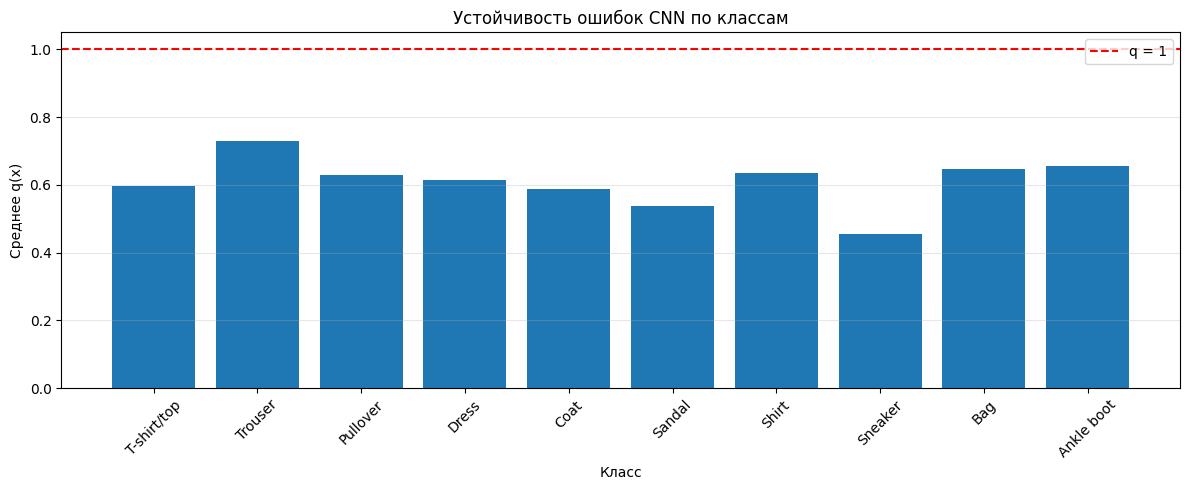

График сохранён в: d:\Учеба\fashion-mnist-cnn-experiments\experiments\fashion_mnist\model_stability\figures\q_average_by_class.png


In [77]:
valid_q_rows = [
    row
    for row in q_by_class
    if row["q_average"] is not None
]

fig, ax = plt.subplots(
    figsize=(12, 5)
)

ax.bar(
    [
        row["class_name"]
        for row in valid_q_rows
    ],
    [
        row["q_average"]
        for row in valid_q_rows
    ],
)

ax.axhline(
    1.0,
    color="red",
    linestyle="--",
    label="q = 1",
)

ax.set_ylim(
    0,
    1.05,
)

ax.set_xlabel(
    "Класс"
)

ax.set_ylabel(
    "Среднее q(x)"
)

ax.set_title(
    "Устойчивость ошибок CNN по классам"
)

ax.tick_params(
    axis="x",
    rotation=45,
)

ax.grid(
    axis="y",
    alpha=0.3,
)

ax.legend()

fig.tight_layout()

stability_figure_path = (
    figures_dir
    / "q_average_by_class.png"
)

fig.savefig(
    stability_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print(
    "График сохранён в:",
    stability_figure_path,
)

### 27. Настройки EDNNA

In [78]:
# EDNNA: настройки эксперимента

from pathlib import Path
import csv
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as torch_F

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from torch.utils.data import DataLoader, Subset

from src.model import FashionCNN
from src.train import fit_two_stage

TARGET_VALIDATION_ACCURACY = 0.92

# # Увеличиваем F-A на 30%
EDNNA_TOTAL_BUDGET = 3240

# Количество изображений,
# добавляемых за одну итерацию.
#
# Это технический параметр, который позволяет
# действительно переобучать CNN несколько раз.
EDNNA_ADD_PER_ITERATION = 200

EDNNA_MAX_ITERATIONS = int(
    math.ceil(
        EDNNA_TOTAL_BUDGET
        / EDNNA_ADD_PER_ITERATION
    )
)

# Размер батча для извлечения признаков
EDNNA_FEATURE_BATCH_SIZE = 512

# Отдельные seed для переобучения
# на каждой итерации EDNNA
EDNNA_SEED_BASE = 1000


ednna_root = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
    / "ednna_plus30"
)

ednna_root.mkdir(
    parents=True,
    exist_ok=True,
)


print(
    "Общий бюджет:",
    EDNNA_TOTAL_BUDGET,
)

print(
    "Добавление за итерацию:",
    EDNNA_ADD_PER_ITERATION,
)

print(
    "Максимальное количество итераций:",
    EDNNA_MAX_ITERATIONS,
)

print(
    "Устройство:",
    device,
)

Общий бюджет: 3240
Добавление за итерацию: 200
Максимальное количество итераций: 17
Устройство: cuda


### 28. Подготовка моделей и загрузчиков

In [79]:
def create_ednna_model():
    """
    Создаёт CNN с архитектурой модели F-A.
    """

    return FashionCNN(
        dropout=fa_training_config[
            "dropout"
        ]
    ).to(device)


def create_ednna_loader(
    dataset,
    shuffle,
    seed=None,
):
    """
    Создаёт DataLoader.

    Для train используется отдельный seed,
    чтобы порядок батчей был воспроизводимым.
    """

    generator = torch.Generator()

    if seed is not None:
        generator.manual_seed(
            int(seed)
        )

    return DataLoader(
        dataset,
        batch_size=(
            fa_training_config[
                "batch_size"
            ]
        ),
        shuffle=shuffle,
        num_workers=0,
        generator=generator,
    )


def forward_with_embedding(
    model,
    images,
):
    """
    Возвращает:

    1. embedding из предпоследнего слоя;
    2. logits классификатора.

    Размер embedding:
    [batch_size, 64]
    """

    x = model.features(images)

    # Flatten
    x = model.classifier[0](x)

    # Linear: 1568 -> 64
    x = model.classifier[1](x)

    # ReLU
    embedding = model.classifier[2](x)

    # Dropout и финальный Linear
    logits = model.classifier[4](
        model.classifier[3](embedding)
    )

    return embedding, logits


def collect_embeddings_and_predictions(
    model,
    dataset,
    device,
    batch_size=512,
):
    """
    Извлекает признаки, метки и предсказания
    для всего dataset.

    Порядок объектов сохраняется.
    """

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
    )

    all_embeddings = []
    all_labels = []
    all_predictions = []

    model.eval()

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            embeddings, logits = (
                forward_with_embedding(
                    model=model,
                    images=images,
                )
            )

            predictions = logits.argmax(
                dim=1
            )

            all_embeddings.append(
                embeddings.detach()
            )

            all_labels.append(
                labels.detach().cpu()
            )

            all_predictions.append(
                predictions.detach().cpu()
            )

    embeddings = torch.cat(
        all_embeddings,
        dim=0,
    )

    labels = torch.cat(
        all_labels,
        dim=0,
    ).numpy()

    predictions = torch.cat(
        all_predictions,
        dim=0,
    ).numpy()

    return (
        embeddings,
        labels,
        predictions,
    )

### 29. Функция отбора кандидатов

In [80]:
def select_ednna_candidates(
    train_embeddings,
    train_labels,
    train_predictions,
    pool_embeddings,
    pool_labels,
):
    """
    Реализует основную логику EDNNA.

    train_embeddings:
        признаки текущей выборки A.

    train_labels:
        истинные метки текущей выборки A.

    train_predictions:
        предсказания CNN на текущей выборке A.

    pool_embeddings:
        признаки резервной выборки B.

    pool_labels:
        истинные метки резервной выборки B.

    Возвращает:

    selected_candidates:
        уникальные кандидаты из B.

    error_count:
        количество ошибок CNN на A.
    """

    train_labels = np.asarray(
        train_labels
    )

    train_predictions = np.asarray(
        train_predictions
    )

    pool_labels = np.asarray(
        pool_labels
    )

    # Нормализация признаков нужна
    # для вычисления cosine distance
    train_embeddings_normalized = (
        torch_F.normalize(
            train_embeddings,
            p=2,
            dim=1,
        )
    )

    pool_embeddings_normalized = (
        torch_F.normalize(
            pool_embeddings,
            p=2,
            dim=1,
        )
    )

    # Ошибочные объекты текущей выборки A
    error_positions = np.flatnonzero(
        train_predictions
        != train_labels
    )

    error_count = int(
        len(error_positions)
    )

    # Словарь нужен для того,
    # чтобы один кандидат не добавлялся
    # несколько раз
    selected_by_candidate = {}

    num_classes = len(CLASS_NAMES)

    for true_class_id in range(
        num_classes
    ):
        for predicted_class_id in range(
            num_classes
        ):
            if (
                true_class_id
                == predicted_class_id
            ):
                continue

            # Оставляем ошибки только
            # конкретного направления i -> j
            direction_mask = (
                train_labels[
                    error_positions
                ]
                == true_class_id
            ) & (
                train_predictions[
                    error_positions
                ]
                == predicted_class_id
            )

            direction_positions = (
                error_positions[
                    direction_mask
                ]
            )

            if len(direction_positions) == 0:
                continue

            # B_i — кандидаты правильного класса
            pool_positions = np.flatnonzero(
                pool_labels
                == true_class_id
            )

            # Если B_i пуст, направление пропускаем
            if len(pool_positions) == 0:
                continue

            # A_j — представители ошибочно
            # предсказанного класса
            train_class_positions = (
                np.flatnonzero(
                    train_labels
                    == predicted_class_id
                )
            )

            error_tensor_positions = (
                torch.as_tensor(
                    direction_positions,
                    dtype=torch.long,
                    device=train_embeddings.device,
                )
            )

            pool_tensor_positions = (
                torch.as_tensor(
                    pool_positions,
                    dtype=torch.long,
                    device=train_embeddings.device,
                )
            )

            x_embeddings = (
                train_embeddings_normalized[
                    error_tensor_positions
                ]
            )

            z_embeddings = (
                pool_embeddings_normalized[
                    pool_tensor_positions
                ]
            )

            # Сходство x с каждым кандидатом z
            similarities_to_candidates = (
                x_embeddings
                @ z_embeddings.T
            )

            best_candidate_local_positions = (
                similarities_to_candidates.argmax(
                    dim=1
                )
            )

            best_candidate_similarities = (
                similarities_to_candidates.gather(
                    1,
                    best_candidate_local_positions[
                        :, None
                    ],
                ).squeeze(1)
            )

            # Косинусное расстояние:
            # distance = 1 - cosine similarity
            candidate_distances = (
                1.0
                - best_candidate_similarities
            )

            # Если A_j пустое,
            # расстояние считается бесконечным
            if len(train_class_positions) == 0:
                wrong_class_distances = (
                    torch.full_like(
                        candidate_distances,
                        float("inf"),
                    )
                )
            else:
                train_class_tensor_positions = (
                    torch.as_tensor(
                        train_class_positions,
                        dtype=torch.long,
                        device=train_embeddings.device,
                    )
                )

                wrong_class_embeddings = (
                    train_embeddings_normalized[
                        train_class_tensor_positions
                    ]
                )

                similarities_to_wrong_class = (
                    x_embeddings
                    @ wrong_class_embeddings.T
                )

                best_wrong_class_similarities = (
                    similarities_to_wrong_class.max(
                        dim=1
                    ).values
                )

                wrong_class_distances = (
                    1.0
                    - best_wrong_class_similarities
                )

            # Главное условие EDNNA:
            #
            # d(f(z), f(x)) < d(f(a), f(x))
            accepted_mask = (
                candidate_distances
                < wrong_class_distances
            )

            accepted_local_positions = (
                np.flatnonzero(
                    accepted_mask.detach()
                    .cpu()
                    .numpy()
                )
            )

            for local_position in (
                accepted_local_positions
            ):
                x_position = int(
                    direction_positions[
                        local_position
                    ]
                )

                candidate_local_position = int(
                    best_candidate_local_positions[
                        local_position
                    ].item()
                )

                candidate_pool_position = int(
                    pool_positions[
                        candidate_local_position
                    ]
                )

                candidate_distance = float(
                    candidate_distances[
                        local_position
                    ].item()
                )

                wrong_class_distance = float(
                    wrong_class_distances[
                        local_position
                    ].item()
                )

                margin = (
                    wrong_class_distance
                    - candidate_distance
                )

                record = {
                    "error_position": x_position,
                    "true_class_id": int(
                        true_class_id
                    ),
                    "predicted_class_id": int(
                        predicted_class_id
                    ),
                    "candidate_pool_position": (
                        candidate_pool_position
                    ),
                    "candidate_distance": (
                        candidate_distance
                    ),
                    "wrong_class_distance": (
                        wrong_class_distance
                    ),
                    "margin": float(margin),
                }

                # Один кандидат может быть найден
                # для нескольких ошибок.
                #
                # Оставляем вариант с максимальным
                # преимуществом по расстоянию.
                previous_record = (
                    selected_by_candidate.get(
                        candidate_pool_position
                    )
                )

                if (
                    previous_record is None
                    or record["margin"]
                    > previous_record["margin"]
                ):
                    selected_by_candidate[
                        candidate_pool_position
                    ] = record

    selected_candidates = list(
        selected_by_candidate.values()
    )

    return (
        selected_candidates,
        error_count,
    )

### 30. Инициализация F-A и F-B

In [81]:
# Текущая выборка A = F-A
current_train_indices = np.asarray(
    fa_indices,
    dtype=np.int64,
).copy()

# Пул дополнительных объектов B = F-B
remaining_pool_indices = np.asarray(
    fb_indices,
    dtype=np.int64,
).copy()

selected_original_indices = []

selection_records = []
iteration_summaries = []


# Загружаем базовую модель F-A
# для первой итерации EDNNA
fa_checkpoint_for_ednna = torch.load(
    fa_checkpoint_path,
    map_location=device,
)

current_model = (
    create_ednna_model()
)

current_model.load_state_dict(
    fa_checkpoint_for_ednna[
        "model_state_dict"
    ]
)

current_model.eval()

ednna_stop_reason = None


initial_validation_accuracy = float(
    fa_checkpoint_for_ednna[
        "validation_accuracy"
    ]
)

print(
    "Начальная validation accuracy:",
    initial_validation_accuracy,
)

if (
    TARGET_VALIDATION_ACCURACY is not None
    and initial_validation_accuracy
    >= TARGET_VALIDATION_ACCURACY
):
    ednna_stop_reason = (
        "target_accuracy_reached_before_selection"
    )

    print(
        "Требуемая точность уже достигнута "
        "до начала отбора."
    )

print(
    "Начальный размер F-A:",
    len(current_train_indices),
)

print(
    "Начальный размер F-B:",
    len(remaining_pool_indices),
)

print(
    "Начальная модель загружена."
)

Начальная validation accuracy: 0.9026666666666666
Начальный размер F-A: 10800
Начальный размер F-B: 43200
Начальная модель загружена.


### 31. Итеративный EDNNA

In [82]:
for iteration in range(
    1,
    EDNNA_MAX_ITERATIONS + 1,
):
    if ednna_stop_reason is not None:
        break

    print()
    print("=" * 80)
    print(
        f"EDNNA iteration {iteration}"
    )
    print("=" * 80)

    already_added = len(
        selected_original_indices
    )

    remaining_budget = (
        EDNNA_TOTAL_BUDGET
        - already_added
    )

    if remaining_budget <= 0:
        ednna_stop_reason = "budget_reached"
        print(
            "Достигнут общий бюджет."
        )
        break

    if len(remaining_pool_indices) == 0:
        ednna_stop_reason = "pool_exhausted"
        print(
            "В F-B больше нет объектов."
        )
        break

    # Текущие A и B
    current_train_dataset = Subset(
        fa_parent_dataset,
        current_train_indices.tolist(),
    )

    current_pool_dataset = Subset(
        fa_parent_dataset,
        remaining_pool_indices.tolist(),
    )

    print(
        "Размер текущей A:",
        len(current_train_dataset),
    )

    print(
        "Размер текущей B:",
        len(current_pool_dataset),
    )

    # Извлекаем признаки A и B
    train_embeddings, train_labels, train_predictions = (
        collect_embeddings_and_predictions(
            model=current_model,
            dataset=current_train_dataset,
            device=device,
            batch_size=EDNNA_FEATURE_BATCH_SIZE,
        )
    )

    pool_embeddings, pool_labels, _ = (
        collect_embeddings_and_predictions(
            model=current_model,
            dataset=current_pool_dataset,
            device=device,
            batch_size=EDNNA_FEATURE_BATCH_SIZE,
        )
    )

    # Проверка соответствия меток
    assert np.array_equal(
        train_labels,
        full_targets[
            current_train_indices
        ],
    )

    assert np.array_equal(
        pool_labels,
        full_targets[
            remaining_pool_indices
        ],
    )

    # Выбор кандидатов по EDNNA
    candidate_records, error_count = (
        select_ednna_candidates(
            train_embeddings=train_embeddings,
            train_labels=train_labels,
            train_predictions=(
                train_predictions
            ),
            pool_embeddings=pool_embeddings,
            pool_labels=pool_labels,
        )
    )

    print(
        "Ошибок модели на текущей A:",
        error_count,
    )

    print(
        "Подходящих уникальных кандидатов:",
        len(candidate_records),
    )

    if len(candidate_records) == 0:
        ednna_stop_reason = "no_candidates"
        print(
            "Подходящие кандидаты не найдены."
        )

        iteration_summaries.append(
            {
                "iteration": int(
                    iteration
                ),
                "errors_in_A": int(
                    error_count
                ),
                "accepted_candidates": 0,
                "selected_this_iteration": 0,
                "train_size_after": int(
                    len(current_train_indices)
                ),
                "pool_size_after": int(
                    len(remaining_pool_indices)
                ),
                "status": "stopped_no_candidates",
            }
        )

        break

    # Сначала выбираем кандидатов
    # с максимальным преимуществом
    # по расстоянию
    candidate_records.sort(
        key=lambda record: (
            -record["margin"],
            record["candidate_distance"],
        )
    )

    number_to_select = min(
        EDNNA_ADD_PER_ITERATION,
        remaining_budget,
        len(candidate_records),
    )

    selected_records_this_iteration = (
        candidate_records[
            :number_to_select
        ]
    )

    selected_pool_positions = np.asarray(
        [
            record[
                "candidate_pool_position"
            ]
            for record in (
                selected_records_this_iteration
            )
        ],
        dtype=np.int64,
    )

    selected_indices_this_iteration = (
        remaining_pool_indices[
            selected_pool_positions
        ]
    )

    # Проверяем отсутствие повторов
    assert len(
        np.unique(
            selected_indices_this_iteration
        )
    ) == len(
        selected_indices_this_iteration
    )

    assert len(
        np.intersect1d(
            current_train_indices,
            selected_indices_this_iteration,
        )
    ) == 0

    # Сохраняем подробности выбора
    for record, original_index in zip(
        selected_records_this_iteration,
        selected_indices_this_iteration,
    ):
        record_with_iteration = dict(
            record
        )

        record_with_iteration[
            "iteration"
        ] = int(iteration)

        record_with_iteration[
            "candidate_original_index"
        ] = int(original_index)

        selection_records.append(
            record_with_iteration
        )

    # Переносим выбранные изображения
    # из B в A
    current_train_indices = np.concatenate(
        [
            current_train_indices,
            selected_indices_this_iteration,
        ]
    )

    remaining_pool_indices = np.delete(
        remaining_pool_indices,
        selected_pool_positions,
    )

    selected_original_indices.extend(
        selected_indices_this_iteration.tolist()
    )

    assert len(
        np.unique(current_train_indices)
    ) == len(current_train_indices)

    print(
        "Добавлено изображений:",
        number_to_select,
    )

    print(
        "Всего добавлено:",
        len(selected_original_indices),
    )

    print(
        "Новый размер A:",
        len(current_train_indices),
    )

    print(
        "Новый размер B:",
        len(remaining_pool_indices),
    )

    # Освобождаем предыдущую модель
    del current_model

    if device.type == "cuda":
        torch.cuda.empty_cache()

    # Переобучение CNN на расширенной A
    iteration_seed = (
        EDNNA_SEED_BASE
        + iteration
    )

    set_seed(iteration_seed)

    augmented_train_dataset = Subset(
        fa_parent_dataset,
        current_train_indices.tolist(),
    )

    ednna_train_loader = (
        create_ednna_loader(
            dataset=augmented_train_dataset,
            shuffle=True,
            seed=iteration_seed,
        )
    )

    ednna_validation_loader = (
        create_ednna_loader(
            dataset=fa_validation_dataset,
            shuffle=False,
            seed=iteration_seed,
        )
    )

    current_model = (
        create_ednna_model()
    )

    criterion = torch.nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        current_model.parameters(),
        lr=fa_training_config[
            "learning_rate"
        ],
        weight_decay=fa_training_config[
            "weight_decay"
        ],
    )

    iteration_root = (
        ednna_root
        / f"iteration_{iteration:02d}"
    )

    checkpoint_path = (
        iteration_root
        / "checkpoints"
        / "best_model.pt"
    )

    history_path = (
        iteration_root
        / "history.json"
    )

    checkpoint_metadata = {
        "experiment": "EDNNA",
        "iteration": int(iteration),
        "seed": int(iteration_seed),
        "train_size": int(
            len(current_train_indices)
        ),
        "pool_size": int(
            len(remaining_pool_indices)
        ),
        "selected_this_iteration": int(
            number_to_select
        ),
        "normalization": (
            fa_normalization_config
        ),
        "architecture": (
            architecture_config
        ),
        "training": (
            fa_training_config
        ),
    }

    fit_two_stage(
        model=current_model,
        train_loader=ednna_train_loader,
        validation_loader=(
            ednna_validation_loader
        ),
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        epochs=fa_training_config[
            "epochs"
        ],
        patience=fa_training_config[
            "early_stopping_patience"
        ],
        min_delta=fa_training_config[
            "min_delta"
        ],
        lr_factor=fa_training_config[
            "learning_rate_factor"
        ],
        checkpoint_path=checkpoint_path,
        history_path=history_path,
        checkpoint_metadata=(
            checkpoint_metadata
        ),
    )

    # Восстанавливаем лучшую модель
    # текущей итерации
    iteration_checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
    )

    current_model.load_state_dict(
        iteration_checkpoint[
            "model_state_dict"
        ]
    )

    current_model.eval()

    iteration_summaries.append(
        {
            "iteration": int(
                iteration
            ),
            "errors_in_A": int(
                error_count
            ),
            "accepted_candidates": int(
                len(candidate_records)
            ),
            "selected_this_iteration": int(
                number_to_select
            ),
            "train_size_after": int(
                len(current_train_indices)
            ),
            "pool_size_after": int(
                len(remaining_pool_indices)
            ),
            "best_epoch": int(
                iteration_checkpoint[
                    "epoch"
                ]
            ),
            "best_stage": int(
                iteration_checkpoint[
                    "stage"
                ]
            ),
            "validation_loss": float(
                iteration_checkpoint[
                    "validation_loss"
                ]
            ),
            "validation_accuracy": float(
                iteration_checkpoint[
                    "validation_accuracy"
                ]
            ),
            "status": "completed",
        }
    )

    current_validation_accuracy = float(
        iteration_checkpoint[
            "validation_accuracy"
        ]
    )

    if (
        TARGET_VALIDATION_ACCURACY is not None
        and current_validation_accuracy
        >= TARGET_VALIDATION_ACCURACY
    ):
        iteration_summaries[-1]["status"] = (
            "stopped_target_accuracy"
        )

        ednna_stop_reason = (
            "target_validation_accuracy_reached"
        )

        print()
        print(
            "Достигнута требуемая validation accuracy:",
            current_validation_accuracy,
        )

        break

    if (
        len(selected_original_indices)
        >= EDNNA_TOTAL_BUDGET
    ):
        iteration_summaries[-1]["status"] = (
            "stopped_budget"
        )

        ednna_stop_reason = "budget_reached"

        print(
            "Достигнут общий бюджет."
        )

        break


set_seed(SEED)

if ednna_stop_reason is None:
    ednna_stop_reason = "max_iterations_reached"

print()
print("EDNNA завершён.")
print(
    "Причина остановки:",
    ednna_stop_reason,
)
print(
    "Всего добавлено:",
    len(selected_original_indices),
)
print(
    "Итоговый размер A:",
    len(current_train_indices),
)
print(
    "Осталось в B:",
    len(remaining_pool_indices),
)


EDNNA iteration 1
Размер текущей A: 10800
Размер текущей B: 43200
Ошибок модели на текущей A: 383
Подходящих уникальных кандидатов: 236
Добавлено изображений: 200
Всего добавлено: 200
Новый размер A: 11000
Новый размер B: 43000
Stage 1 | Epoch 001 | lr: 0.001000 | train loss: 0.8426 | train accuracy: 0.7043 | validation loss: 0.4966 | validation accuracy: 0.8157
Stage 1 | Epoch 002 | lr: 0.001000 | train loss: 0.5267 | train accuracy: 0.8101 | validation loss: 0.4041 | validation accuracy: 0.8510
Stage 1 | Epoch 003 | lr: 0.001000 | train loss: 0.4411 | train accuracy: 0.8408 | validation loss: 0.3852 | validation accuracy: 0.8590
Stage 1 | Epoch 004 | lr: 0.001000 | train loss: 0.4022 | train accuracy: 0.8553 | validation loss: 0.3454 | validation accuracy: 0.8755
Stage 1 | Epoch 005 | lr: 0.001000 | train loss: 0.3615 | train accuracy: 0.8672 | validation loss: 0.3166 | validation accuracy: 0.8832
Stage 1 | Epoch 006 | lr: 0.001000 | train loss: 0.3387 | train accuracy: 0.8741 | val

### 32. Сохранение результатов отбора

In [83]:
selection_dir = (
    ednna_root / "selection"
)

metrics_dir = (
    ednna_root / "metrics"
)

figures_dir = (
    ednna_root / "figures"
)

selection_dir.mkdir(
    parents=True,
    exist_ok=True,
)

metrics_dir.mkdir(
    parents=True,
    exist_ok=True,
)

figures_dir.mkdir(
    parents=True,
    exist_ok=True,
)


selected_original_indices_array = (
    np.asarray(
        selected_original_indices,
        dtype=np.int64,
    )
)


np.savez(
    selection_dir
    / "selected_indices.npz",
    selected_indices=(
        selected_original_indices_array
    ),
    final_train_indices=(
        current_train_indices
    ),
    remaining_pool_indices=(
        remaining_pool_indices
    ),
)


# Сохраняем подробности отбора
selection_records_path = (
    selection_dir
    / "selection_records.csv"
)

selection_fieldnames = [
    "iteration",
    "error_position",
    "true_class_id",
    "predicted_class_id",
    "candidate_pool_position",
    "candidate_original_index",
    "candidate_distance",
    "wrong_class_distance",
    "margin",
]

with selection_records_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:
    writer = csv.DictWriter(
        csv_file,
        fieldnames=selection_fieldnames,
    )

    writer.writeheader()

    for record in selection_records:
        writer.writerow(record)


# Сохраняем сводку по итерациям
iteration_summary_path = (
    metrics_dir
    / "iteration_summary.csv"
)

iteration_fieldnames = [
    "iteration",
    "errors_in_A",
    "accepted_candidates",
    "selected_this_iteration",
    "train_size_after",
    "pool_size_after",
    "best_epoch",
    "best_stage",
    "validation_loss",
    "validation_accuracy",
    "status",
]

with iteration_summary_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:
    writer = csv.DictWriter(
        csv_file,
        fieldnames=iteration_fieldnames,
    )

    writer.writeheader()

    for row in iteration_summaries:
        writer.writerow(row)


ednna_metadata = {
    "experiment": "EDNNA",
    "initial_dataset": "F-A",
    "candidate_dataset": "F-B",
    "total_budget": int(
        EDNNA_TOTAL_BUDGET
    ),
    "add_per_iteration": int(
        EDNNA_ADD_PER_ITERATION
    ),
    "target_validation_accuracy": float(
        TARGET_VALIDATION_ACCURACY
    ),
    "stop_reason": ednna_stop_reason,
    "initial_train_size": int(
        len(fa_indices)
    ),
    "final_train_size": int(
        len(current_train_indices)
    ),
    "selected_count": int(
        len(selected_original_indices)
    ),
    "device": str(device),
    "iteration_summaries": (
        iteration_summaries
    ),
}

metadata_path = (
    metrics_dir
    / "ednna_metadata.json"
)

metadata_path.write_text(
    json.dumps(
        ednna_metadata,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


print(
    "Результаты EDNNA сохранены в:",
    ednna_root,
)

Результаты EDNNA сохранены в: d:\Учеба\fashion-mnist-cnn-experiments\experiments\fashion_mnist\ednna_plus30


### 33. Финальная оценка EDNNA на test

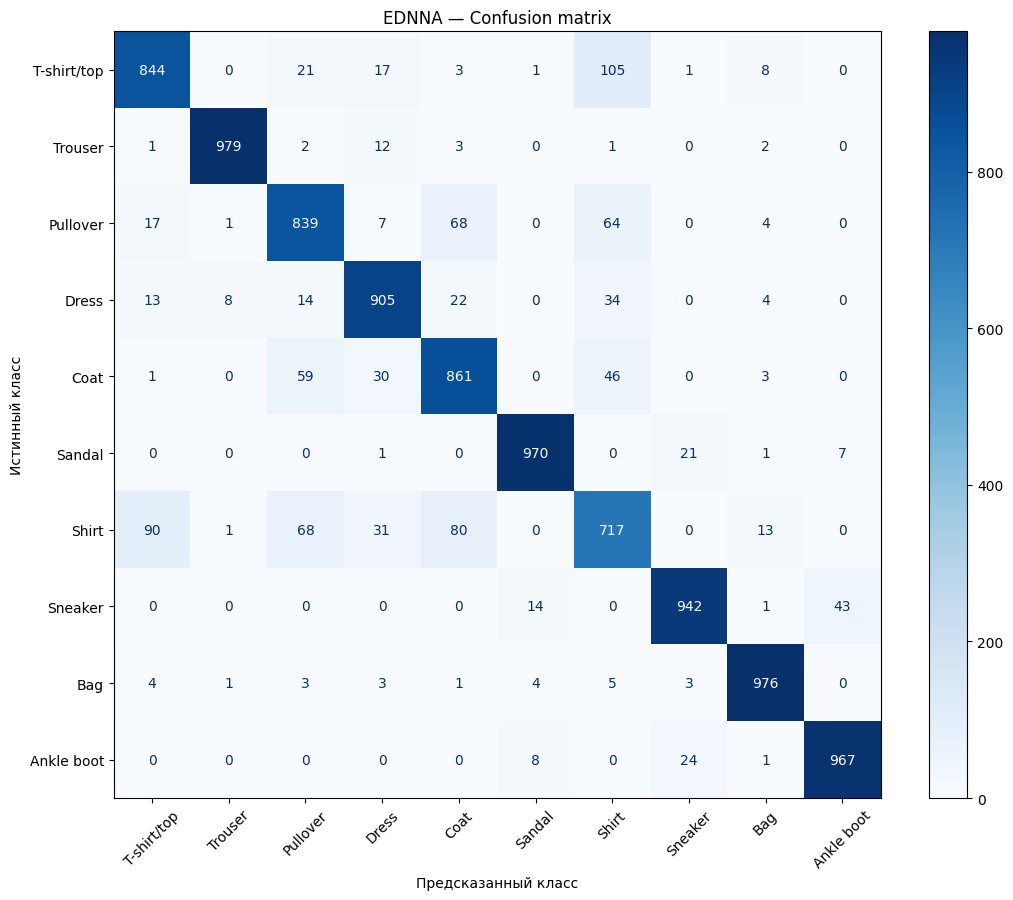

EDNNA Test Accuracy: 0.9
EDNNA Macro-F1: 0.8997944685919335
Добавлено изображений: 3240
Финальный размер F-A: 14040


In [84]:
def collect_predictions_only(
    model,
    dataset,
    device,
    batch_size=512,
):
    """
    Получает labels и predictions
    без извлечения embedding.
    """

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
    )

    all_labels = []
    all_predictions = []

    model.eval()

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            logits = model(images)

            predictions = logits.argmax(
                dim=1
            )

            all_labels.append(
                labels.detach()
                .cpu()
                .numpy()
            )

            all_predictions.append(
                predictions.detach()
                .cpu()
                .numpy()
            )

    return (
        np.concatenate(all_labels),
        np.concatenate(all_predictions),
    )


ednna_test_y_true, ednna_test_y_pred = (
    collect_predictions_only(
        model=current_model,
        dataset=fa_test_dataset,
        device=device,
        batch_size=EDNNA_FEATURE_BATCH_SIZE,
    )
)


ednna_test_accuracy = accuracy_score(
    ednna_test_y_true,
    ednna_test_y_pred,
)

ednna_macro_f1 = f1_score(
    ednna_test_y_true,
    ednna_test_y_pred,
    average="macro",
    zero_division=0,
)


ednna_confusion = confusion_matrix(
    ednna_test_y_true,
    ednna_test_y_pred,
    labels=np.arange(
        len(CLASS_NAMES)
    ),
)


# Метрики по классам
ednna_test_confusion, ednna_test_rows = calculate_per_class_metrics(
    ednna_test_y_true,
    ednna_test_y_pred,
    class_names=CLASS_NAMES,
)

save_per_class_metrics(
    ednna_test_rows,
    metrics_dir
    / "test_per_class_metrics.csv",
)


# Общие метрики
ednna_test_metrics = {
    "experiment": "EDNNA",
    "train_size": int(
        len(current_train_indices)
    ),
    "test_size": int(
        len(fa_test_dataset)
    ),
    "selected_count": int(
        len(selected_original_indices)
    ),
    "test_accuracy": float(
        ednna_test_accuracy
    ),
    "macro_f1": float(
        ednna_macro_f1
    ),
    "seed": int(SEED),
}


(metrics_dir / "test_metrics.json").write_text(
    json.dumps(
        ednna_test_metrics,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


# Матрица ошибок в CSV
confusion_csv_path = (
    metrics_dir
    / "confusion_matrix.csv"
)

with confusion_csv_path.open(
    "w",
    newline="",
    encoding="utf-8",
) as csv_file:
    writer = csv.writer(csv_file)

    writer.writerow(
        ["true_class"]
        + list(CLASS_NAMES)
    )

    for class_name, row in zip(
        CLASS_NAMES,
        ednna_confusion,
    ):
        writer.writerow(
            [class_name]
            + row.tolist()
        )


# Матрица ошибок в PNG
fig, ax = plt.subplots(
    figsize=(11, 9)
)

display = ConfusionMatrixDisplay(
    confusion_matrix=ednna_confusion,
    display_labels=CLASS_NAMES,
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=True,
)

ax.set_title(
    "EDNNA — Confusion matrix"
)

ax.set_xlabel(
    "Предсказанный класс"
)

ax.set_ylabel(
    "Истинный класс"
)

fig.tight_layout()

confusion_figure_path = (
    figures_dir
    / "confusion_matrix.png"
)

fig.savefig(
    confusion_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)


print(
    "EDNNA Test Accuracy:",
    ednna_test_accuracy,
)

print(
    "EDNNA Macro-F1:",
    ednna_macro_f1,
)

print(
    "Добавлено изображений:",
    len(selected_original_indices),
)

print(
    "Финальный размер F-A:",
    len(current_train_indices),
)

In [85]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path(
    r"D:\Учеба\fashion-mnist-cnn-experiments"
)

experiments_root = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
)


experiment_specs = [
    {
        "name": "Full F baseline",
        "folder": "baseline",
    },
    {
        "name": "F-A baseline",
        "folder": "fa_baseline",
    },
    {
        "name": "Strategy 1",
        "folder": "strategy_1_centroid",
    },
    {
        "name": "Strategy 2",
        "folder": "strategy_2_hard_examples",
    },
    {
        "name": "EDNNA +1000",
        "folder": "ednna",
    },
    {
        "name": "EDNNA +20%",
        "folder": "ednna_plus20",
    },
    {
        "name": "EDNNA +30%",
        "folder": "ednna_plus30",
    },
]


comparison_rows = []

for experiment in experiment_specs:
    experiment_root = (
        experiments_root
        / experiment["folder"]
    )

    metrics_path = (
        experiment_root
        / "metrics"
        / "test_metrics.json"
    )

    metadata_path = (
        experiment_root
        / "metrics"
        / "ednna_metadata.json"
    )

    if not metrics_path.exists():
        print(
            "Файл не найден:",
            metrics_path,
        )
        continue

    with metrics_path.open(
        "r",
        encoding="utf-8",
    ) as file:
        metrics = json.load(file)

    metadata = {}

    if metadata_path.exists():
        with metadata_path.open(
            "r",
            encoding="utf-8",
        ) as file:
            metadata = json.load(file)

    comparison_rows.append(
        {
            "Модель": experiment["name"],
            "Размер train": metrics.get(
                "train_size"
            ),
            "Добавлено изображений": metrics.get(
                "selected_count"
            ),
            "Test Accuracy": metrics.get(
                "test_accuracy"
            ),
            "Macro-F1": metrics.get(
                "macro_f1"
            ),
            "Validation Accuracy": metrics.get(
                "validation_accuracy"
            ),
            "Причина остановки": metadata.get(
                "stop_reason"
            ),
        }
    )


comparison_table = pd.DataFrame(
    comparison_rows
)


# Сравнение с базовой моделью F-A
fa_baseline_row = comparison_table[
    comparison_table["Модель"]
    == "F-A baseline"
]

if len(fa_baseline_row) > 0:
    fa_baseline_accuracy = float(
        fa_baseline_row.iloc[0][
            "Test Accuracy"
        ]
    )

    fa_baseline_macro_f1 = float(
        fa_baseline_row.iloc[0][
            "Macro-F1"
        ]
    )

    comparison_table[
        "Δ Accuracy vs F-A"
    ] = (
        comparison_table["Test Accuracy"]
        - fa_baseline_accuracy
    )

    comparison_table[
        "Δ Macro-F1 vs F-A"
    ] = (
        comparison_table["Macro-F1"]
        - fa_baseline_macro_f1
    )


comparison_table = comparison_table[
    [
        "Модель",
        "Размер train",
        "Добавлено изображений",
        "Test Accuracy",
        "Macro-F1",
        "Validation Accuracy",
        "Δ Accuracy vs F-A",
        "Δ Macro-F1 vs F-A",
        "Причина остановки",
    ]
]


display(
    comparison_table.style.format(
        {
            "Test Accuracy": "{:.4f}",
            "Macro-F1": "{:.6f}",
            "Validation Accuracy": "{:.4f}",
            "Δ Accuracy vs F-A": "{:+.4f}",
            "Δ Macro-F1 vs F-A": "{:+.6f}",
        },
        na_rep="—",
    ).set_caption(
        "Сравнение моделей на тестовой выборке"
    )
)


comparison_dir = (
    experiments_root
    / "comparison"
)

comparison_dir.mkdir(
    parents=True,
    exist_ok=True,
)

comparison_table.to_csv(
    comparison_dir
    / "all_models_comparison.csv",
    index=False,
    encoding="utf-8-sig",
)

print()
print(
    "Таблица сохранена в:",
    comparison_dir
    / "all_models_comparison.csv",
)

,Модель,Размер train,Добавлено изображений,Test Accuracy,Macro-F1,Validation Accuracy,Δ Accuracy vs F-A,Δ Macro-F1 vs F-A,Причина остановки
0,Full F baseline,54000.000000,—,0.9200,0.919747,0.9312,+0.0270,+0.027072,—
1,F-A baseline,10800.000000,—,0.8930,0.892675,0.9027,+0.0000,+0.000000,—
2,Strategy 1,—,—,0.8940,0.893462,0.9013,+0.0010,+0.000787,—
3,Strategy 2,—,—,0.8947,0.893772,0.9037,+0.0017,+0.001097,—
4,EDNNA +1000,11800.000000,1000.000000,0.8927,0.893094,—,-0.0003,+0.000419,—
5,EDNNA +20%,12960.000000,2160.000000,0.8996,0.899315,—,+0.0066,+0.006640,target_validation_accuracy_reached
6,EDNNA +30%,14040.000000,3240.000000,0.9000,0.899794,—,+0.0070,+0.007119,budget_reached



Таблица сохранена в: D:\Учеба\fashion-mnist-cnn-experiments\experiments\fashion_mnist\comparison\all_models_comparison.csv


In [86]:
direction_experiments = [
    {
        "Модель": "F-A baseline",
        "folder": "fa_baseline",
    },
    {
        "Модель": "EDNNA +1000",
        "folder": "ednna",
    },
    {
        "Модель": "EDNNA +20%",
        "folder": "ednna_plus20",
    },
    {
        "Модель": "EDNNA +30%",
        "folder": "ednna_plus30",
    },
]


direction_rows = []

for experiment in direction_experiments:
    confusion_path = (
        experiments_root
        / experiment["folder"]
        / "metrics"
        / "confusion_matrix.csv"
    )

    if not confusion_path.exists():
        continue

    confusion_df = pd.read_csv(
        confusion_path,
        index_col=0,
    )

    shirt_to_tshirt = int(
        confusion_df.loc[
            "Shirt",
            "T-shirt/top",
        ]
    )

    tshirt_to_shirt = int(
        confusion_df.loc[
            "T-shirt/top",
            "Shirt",
        ]
    )

    direction_rows.append(
        {
            "Модель": experiment["Модель"],
            "Shirt → T-shirt/top": (
                shirt_to_tshirt
            ),
            "T-shirt/top → Shirt": (
                tshirt_to_shirt
            ),
            "Всего ошибок между классами": (
                shirt_to_tshirt
                + tshirt_to_shirt
            ),
        }
    )


direction_table = pd.DataFrame(
    direction_rows
)

display(
    direction_table.style.set_caption(
        "Сравнение направленных ошибок"
    )
)


direction_table.to_csv(
    comparison_dir
    / "directed_errors_comparison.csv",
    index=False,
    encoding="utf-8-sig",
)

,Модель,Shirt → T-shirt/top,T-shirt/top → Shirt,Всего ошибок между классами
0,F-A baseline,120,103,223
1,EDNNA +1000,103,121,224
2,EDNNA +20%,114,103,217
3,EDNNA +30%,90,105,195


### 34. Настройки случайных стратегий

In [87]:
### 34. Настройки случайных стратегий

from pathlib import Path
import csv
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from torch.utils.data import Subset


if "PROJECT_ROOT" not in globals():
    PROJECT_ROOT = Path(
        r"D:\Учеба\fashion-mnist-cnn-experiments"
    )


experiments_root = (
    PROJECT_ROOT
    / "experiments"
    / "fashion_mnist"
)


# Берём ровно столько объектов,
# сколько было выбрано EDNNA +30%
ednna_reference_root = (
    experiments_root
    / "ednna_plus30"
)

ednna_reference_metrics_path = (
    ednna_reference_root
    / "metrics"
    / "test_metrics.json"
)

with ednna_reference_metrics_path.open(
    "r",
    encoding="utf-8",
) as file:
    ednna_reference_metrics = json.load(file)


RANDOM_SELECTION_COUNT = int(
    ednna_reference_metrics[
        "selected_count"
    ]
)


# Отдельные seed для случайного отбора
RANDOM_UNIFORM_SELECTION_SEED = 2026
RANDOM_CLASS_SELECTION_SEED = 2027

# Для честного сравнения обе модели
# обучаются с одинаковым seed
RANDOM_TRAIN_SEED = 3000


random_experiments_root = (
    experiments_root
    / "random_selection"
)

random_experiments_root.mkdir(
    parents=True,
    exist_ok=True,
)


print(
    "Количество изображений для отбора:",
    RANDOM_SELECTION_COUNT,
)

print(
    "Seed равномерного случайного отбора:",
    RANDOM_UNIFORM_SELECTION_SEED,
)

print(
    "Seed случайного отбора по классам:",
    RANDOM_CLASS_SELECTION_SEED,
)

print(
    "Seed обучения моделей:",
    RANDOM_TRAIN_SEED,
)

Количество изображений для отбора: 3240
Seed равномерного случайного отбора: 2026
Seed случайного отбора по классам: 2027
Seed обучения моделей: 3000


### 35. Отбор случайных изображений

In [88]:
### 35. Отбор случайных изображений


def select_uniform_random_indices(
    pool_indices,
    number_to_select,
    seed,
):
    """
    Равномерный случайный отбор
    из всего пула F-B.
    """

    pool_indices = np.asarray(
        pool_indices,
        dtype=np.int64,
    )

    if number_to_select > len(pool_indices):
        raise ValueError(
            "Нельзя выбрать больше объектов, "
            "чем есть в пуле B."
        )

    rng = np.random.default_rng(seed)

    selected_positions = rng.choice(
        len(pool_indices),
        size=number_to_select,
        replace=False,
    )

    selected_indices = pool_indices[
        selected_positions
    ]

    return np.sort(
        selected_indices
    )


def allocate_error_proportional_quotas(
    error_class_counts,
    pool_class_counts,
    total_to_select,
):
    """
    Распределяет общее количество объектов
    по классам пропорционально числу ошибок
    каждого истинного класса.
    """

    error_class_counts = np.asarray(
        error_class_counts,
        dtype=np.int64,
    )

    pool_class_counts = np.asarray(
        pool_class_counts,
        dtype=np.int64,
    )

    if total_to_select > pool_class_counts.sum():
        raise ValueError(
            "Запрошено больше объектов, "
            "чем есть в пуле B."
        )

    total_errors = int(
        error_class_counts.sum()
    )

    # Если ошибок нет, используем
    # равномерное распределение по классам
    if total_errors == 0:
        weights = (
            pool_class_counts
            / pool_class_counts.sum()
        )
    else:
        weights = (
            error_class_counts
            / total_errors
        )

    raw_quotas = (
        weights
        * total_to_select
    )

    quotas = np.floor(
        raw_quotas
    ).astype(np.int64)

    # Нельзя выбрать из класса больше,
    # чем есть в пуле B
    quotas = np.minimum(
        quotas,
        pool_class_counts,
    )

    remaining = int(
        total_to_select
        - quotas.sum()
    )

    # Распределяем остаток по классам
    # с наибольшей недостающей долей
    while remaining > 0:
        available_classes = np.flatnonzero(
            quotas < pool_class_counts
        )

        if len(available_classes) == 0:
            raise ValueError(
                "Невозможно распределить "
                "требуемое количество объектов."
            )

        deficits = (
            raw_quotas
            - quotas
        )

        selected_class = available_classes[
            np.argmax(
                deficits[
                    available_classes
                ]
            )
        ]

        quotas[selected_class] += 1
        remaining -= 1

    return quotas


def select_random_by_error_class(
    pool_indices,
    pool_labels,
    error_class_counts,
    number_to_select,
    seed,
):
    """
    Случайный отбор из F-B,
    но количество объектов каждого класса
    пропорционально доле ошибок этого класса.
    """

    pool_indices = np.asarray(
        pool_indices,
        dtype=np.int64,
    )

    pool_labels = np.asarray(
        pool_labels,
        dtype=np.int64,
    )

    number_of_classes = len(
        CLASS_NAMES
    )

    pool_class_counts = np.bincount(
        pool_labels,
        minlength=number_of_classes,
    )

    class_quotas = (
        allocate_error_proportional_quotas(
            error_class_counts=(
                error_class_counts
            ),
            pool_class_counts=(
                pool_class_counts
            ),
            total_to_select=(
                number_to_select
            ),
        )
    )

    rng = np.random.default_rng(seed)

    selected_indices = []

    for class_id, quota in enumerate(
        class_quotas
    ):
        if quota == 0:
            continue

        class_pool_positions = np.flatnonzero(
            pool_labels == class_id
        )

        selected_class_positions = (
            rng.choice(
                class_pool_positions,
                size=int(quota),
                replace=False,
            )
        )

        selected_indices.extend(
            pool_indices[
                selected_class_positions
            ].tolist()
        )

    selected_indices = np.asarray(
        selected_indices,
        dtype=np.int64,
    )

    rng.shuffle(
        selected_indices
    )

    return (
        np.sort(selected_indices),
        class_quotas,
    )


# Индексы исходных изображений
fa_indices_array = np.asarray(
    fa_indices,
    dtype=np.int64,
)

fb_indices_array = np.asarray(
    fb_indices,
    dtype=np.int64,
)

full_targets_array = np.asarray(
    full_targets
)


# Загружаем базовую модель F-A
# для подсчёта ошибок по классам
random_reference_model = (
    create_ednna_model()
)

random_reference_checkpoint = (
    torch.load(
        fa_checkpoint_path,
        map_location=device,
    )
)

random_reference_model.load_state_dict(
    random_reference_checkpoint[
        "model_state_dict"
    ]
)

random_reference_model.eval()


fa_error_y_true, fa_error_y_pred = (
    collect_predictions_only(
        model=random_reference_model,
        dataset=fa_dataset,
        device=device,
        batch_size=EDNNA_FEATURE_BATCH_SIZE,
    )
)


assert np.array_equal(
    fa_error_y_true,
    full_targets_array[
        fa_indices_array
    ],
)


# Ошибки считаются по истинному классу
error_mask = (
    fa_error_y_true
    != fa_error_y_pred
)

error_class_counts = np.bincount(
    fa_error_y_true[
        error_mask
    ],
    minlength=len(CLASS_NAMES),
)


pool_labels_array = (
    full_targets_array[
        fb_indices_array
    ]
)

pool_class_counts = np.bincount(
    pool_labels_array,
    minlength=len(CLASS_NAMES),
)


# Стратегия 1:
# равномерный случайный отбор
random_uniform_indices = (
    select_uniform_random_indices(
        pool_indices=fb_indices_array,
        number_to_select=(
            RANDOM_SELECTION_COUNT
        ),
        seed=(
            RANDOM_UNIFORM_SELECTION_SEED
        ),
    )
)


# Стратегия 2:
# случайный отбор по доле ошибок классов
(
    random_error_class_indices,
    random_error_class_quotas,
) = select_random_by_error_class(
    pool_indices=fb_indices_array,
    pool_labels=pool_labels_array,
    error_class_counts=(
        error_class_counts
    ),
    number_to_select=(
        RANDOM_SELECTION_COUNT
    ),
    seed=(
        RANDOM_CLASS_SELECTION_SEED
    ),
)


print(
    "Ошибки F-A по истинным классам:"
)

for class_id, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"{class_id}: {class_name} — "
        f"{error_class_counts[class_id]}"
    )


allocation_table = pd.DataFrame(
    {
        "Класс": CLASS_NAMES,
        "Ошибки F-A": error_class_counts,
        "Объектов в F-B": pool_class_counts,
        "Квота случайной стратегии": (
            random_error_class_quotas
        ),
    }
)

display(
    allocation_table
)

Ошибки F-A по истинным классам:
0: T-shirt/top — 58
1: Trouser — 2
2: Pullover — 65
3: Dress — 28
4: Coat — 51
5: Sandal — 2
6: Shirt — 146
7: Sneaker — 10
8: Bag — 4
9: Ankle boot — 17


,Класс,Ошибки F-A,Объектов в F-B,Квота случайной стратегии
0,T-shirt/top,58,4320,491
1,Trouser,2,4320,17
2,Pullover,65,4320,550
3,Dress,28,4320,237
4,Coat,51,4320,431
5,Sandal,2,4320,17
6,Shirt,146,4320,1235
7,Sneaker,10,4320,84
8,Bag,4,4320,34
9,Ankle boot,17,4320,144


### 36. Общая функция обучения случайной стратегии

In [89]:
### 36. Обучение и оценка случайной стратегии


def run_random_experiment(
    experiment_name,
    experiment_folder,
    selected_indices,
    selection_method,
    selection_seed,
    train_seed,
    selection_metadata=None,
):
    """
    Обучает CNN на F-A плюс выбранные
    случайные изображения и сохраняет результаты.
    """

    selected_indices = np.asarray(
        selected_indices,
        dtype=np.int64,
    )

    final_train_indices = np.concatenate(
        [
            fa_indices_array,
            selected_indices,
        ]
    )

    # Проверки
    assert len(
        np.unique(final_train_indices)
    ) == len(final_train_indices)

    assert len(
        np.intersect1d(
            fa_indices_array,
            selected_indices,
        )
    ) == 0

    experiment_root = (
        random_experiments_root
        / experiment_folder
    )

    checkpoints_dir = (
        experiment_root
        / "checkpoints"
    )

    metrics_dir_random = (
        experiment_root
        / "metrics"
    )

    figures_dir_random = (
        experiment_root
        / "figures"
    )

    selection_dir_random = (
        experiment_root
        / "selection"
    )

    checkpoints_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    metrics_dir_random.mkdir(
        parents=True,
        exist_ok=True,
    )

    figures_dir_random.mkdir(
        parents=True,
        exist_ok=True,
    )

    selection_dir_random.mkdir(
        parents=True,
        exist_ok=True,
    )

    # Фиксируем seed обучения
    set_seed(train_seed)

    train_dataset_random = Subset(
        fa_parent_dataset,
        final_train_indices.tolist(),
    )

    train_loader_random = (
        create_ednna_loader(
            dataset=train_dataset_random,
            shuffle=True,
            seed=train_seed,
        )
    )

    validation_loader_random = (
        create_ednna_loader(
            dataset=fa_validation_dataset,
            shuffle=False,
            seed=train_seed,
        )
    )

    random_model = (
        create_ednna_model()
    )

    criterion_random = (
        torch.nn.CrossEntropyLoss()
    )

    optimizer_random = (
        torch.optim.Adam(
            random_model.parameters(),
            lr=fa_training_config[
                "learning_rate"
            ],
            weight_decay=fa_training_config[
                "weight_decay"
            ],
        )
    )

    checkpoint_path_random = (
        checkpoints_dir
        / "best_model.pt"
    )

    history_path_random = (
        experiment_root
        / "history.json"
    )

    checkpoint_metadata_random = {
        "experiment": experiment_name,
        "selection_method": selection_method,
        "selection_seed": int(
            selection_seed
        ),
        "train_seed": int(
            train_seed
        ),
        "train_size": int(
            len(final_train_indices)
        ),
        "selected_count": int(
            len(selected_indices)
        ),
    }

    fit_two_stage(
        model=random_model,
        train_loader=train_loader_random,
        validation_loader=(
            validation_loader_random
        ),
        criterion=criterion_random,
        optimizer=optimizer_random,
        device=device,
        epochs=fa_training_config[
            "epochs"
        ],
        patience=fa_training_config[
            "early_stopping_patience"
        ],
        min_delta=fa_training_config[
            "min_delta"
        ],
        lr_factor=fa_training_config[
            "learning_rate_factor"
        ],
        checkpoint_path=(
            checkpoint_path_random
        ),
        history_path=(
            history_path_random
        ),
        checkpoint_metadata=(
            checkpoint_metadata_random
        ),
    )

    # Загружаем лучшую эпоху
    checkpoint_random = torch.load(
        checkpoint_path_random,
        map_location=device,
    )

    random_model.load_state_dict(
        checkpoint_random[
            "model_state_dict"
        ]
    )

    random_model.eval()

    # Финальная оценка на test
    random_y_true, random_y_pred = (
        collect_predictions_only(
            model=random_model,
            dataset=fa_test_dataset,
            device=device,
            batch_size=EDNNA_FEATURE_BATCH_SIZE,
        )
    )

    random_test_accuracy = (
        accuracy_score(
            random_y_true,
            random_y_pred,
        )
    )

    random_macro_f1 = f1_score(
        random_y_true,
        random_y_pred,
        average="macro",
        zero_division=0,
    )

    random_confusion = confusion_matrix(
        random_y_true,
        random_y_pred,
        labels=np.arange(
            len(CLASS_NAMES)
        ),
    )

    _, random_per_class_rows = (
        calculate_per_class_metrics(
            random_y_true,
            random_y_pred,
            CLASS_NAMES,
        )
    )

    save_per_class_metrics(
        random_per_class_rows,
        metrics_dir_random
        / "test_per_class_metrics.csv",
    )

    # Сохраняем confusion matrix в CSV
    confusion_csv_path_random = (
        metrics_dir_random
        / "confusion_matrix.csv"
    )

    with confusion_csv_path_random.open(
        "w",
        newline="",
        encoding="utf-8",
    ) as csv_file:
        writer = csv.writer(csv_file)

        writer.writerow(
            ["true_class"]
            + list(CLASS_NAMES)
        )

        for class_name, row in zip(
            CLASS_NAMES,
            random_confusion,
        ):
            writer.writerow(
                [class_name]
                + row.tolist()
            )

    # Сохраняем confusion matrix в PNG
    fig, ax = plt.subplots(
        figsize=(11, 9)
    )

    display_random = (
        ConfusionMatrixDisplay(
            confusion_matrix=(
                random_confusion
            ),
            display_labels=CLASS_NAMES,
        )
    )

    display_random.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        xticks_rotation=45,
        colorbar=True,
    )

    ax.set_title(
        f"{experiment_name} — Confusion matrix"
    )

    ax.set_xlabel(
        "Предсказанный класс"
    )

    ax.set_ylabel(
        "Истинный класс"
    )

    fig.tight_layout()

    fig.savefig(
        figures_dir_random
        / "confusion_matrix.png",
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    # Сохраняем выбранные индексы
    np.savez(
        selection_dir_random
        / "selected_indices.npz",
        selected_indices=(
            selected_indices
        ),
        final_train_indices=(
            final_train_indices
        ),
        initial_train_indices=(
            fa_indices_array
        ),
    )

    selection_metadata_random = {
        "experiment": experiment_name,
        "selection_method": selection_method,
        "selection_seed": int(
            selection_seed
        ),
        "train_seed": int(
            train_seed
        ),
        "initial_train_size": int(
            len(fa_indices_array)
        ),
        "selected_count": int(
            len(selected_indices)
        ),
        "final_train_size": int(
            len(final_train_indices)
        ),
        "selection_metadata": (
            selection_metadata or {}
        ),
        "stop_reason": "fixed_budget",
        "device": str(device),
    }

    (
        selection_dir_random
        / "selection_metadata.json"
    ).write_text(
        json.dumps(
            selection_metadata_random,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

    # Сохраняем итоговые метрики
    random_metrics = {
        "experiment": experiment_name,
        "train_size": int(
            len(final_train_indices)
        ),
        "validation_size": int(
            len(fa_validation_dataset)
        ),
        "test_size": int(
            len(fa_test_dataset)
        ),
        "selected_count": int(
            len(selected_indices)
        ),
        "checkpoint_epoch": int(
            checkpoint_random["epoch"]
        ),
        "checkpoint_stage": int(
            checkpoint_random["stage"]
        ),
        "validation_loss": float(
            checkpoint_random[
                "validation_loss"
            ]
        ),
        "validation_accuracy": float(
            checkpoint_random[
                "validation_accuracy"
            ]
        ),
        "test_accuracy": float(
            random_test_accuracy
        ),
        "macro_f1": float(
            random_macro_f1
        ),
        "selection_method": selection_method,
        "selection_seed": int(
            selection_seed
        ),
        "train_seed": int(
            train_seed
        ),
    }

    (
        metrics_dir_random
        / "test_metrics.json"
    ).write_text(
        json.dumps(
            random_metrics,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

    print()
    print(
        f"{experiment_name} завершён."
    )
    print(
        "Добавлено изображений:",
        len(selected_indices),
    )
    print(
        "Размер train:",
        len(final_train_indices),
    )
    print(
        "Test Accuracy:",
        random_test_accuracy,
    )
    print(
        "Macro-F1:",
        random_macro_f1,
    )

    return random_metrics

### 37. Запуск двух случайных алгоритмов

Stage 1 | Epoch 001 | lr: 0.001000 | train loss: 0.7380 | train accuracy: 0.7373 | validation loss: 0.4313 | validation accuracy: 0.8462
Stage 1 | Epoch 002 | lr: 0.001000 | train loss: 0.4545 | train accuracy: 0.8390 | validation loss: 0.3669 | validation accuracy: 0.8653
Stage 1 | Epoch 003 | lr: 0.001000 | train loss: 0.3954 | train accuracy: 0.8564 | validation loss: 0.3246 | validation accuracy: 0.8810
Stage 1 | Epoch 004 | lr: 0.001000 | train loss: 0.3432 | train accuracy: 0.8779 | validation loss: 0.3106 | validation accuracy: 0.8867
Stage 1 | Epoch 005 | lr: 0.001000 | train loss: 0.3221 | train accuracy: 0.8806 | validation loss: 0.3027 | validation accuracy: 0.8870
Stage 1 | Epoch 006 | lr: 0.001000 | train loss: 0.2967 | train accuracy: 0.8902 | validation loss: 0.3014 | validation accuracy: 0.8920
Stage 1 | Epoch 007 | lr: 0.001000 | train loss: 0.2805 | train accuracy: 0.8964 | validation loss: 0.2989 | validation accuracy: 0.8902
Stage 1 | Epoch 008 | lr: 0.001000 | trai

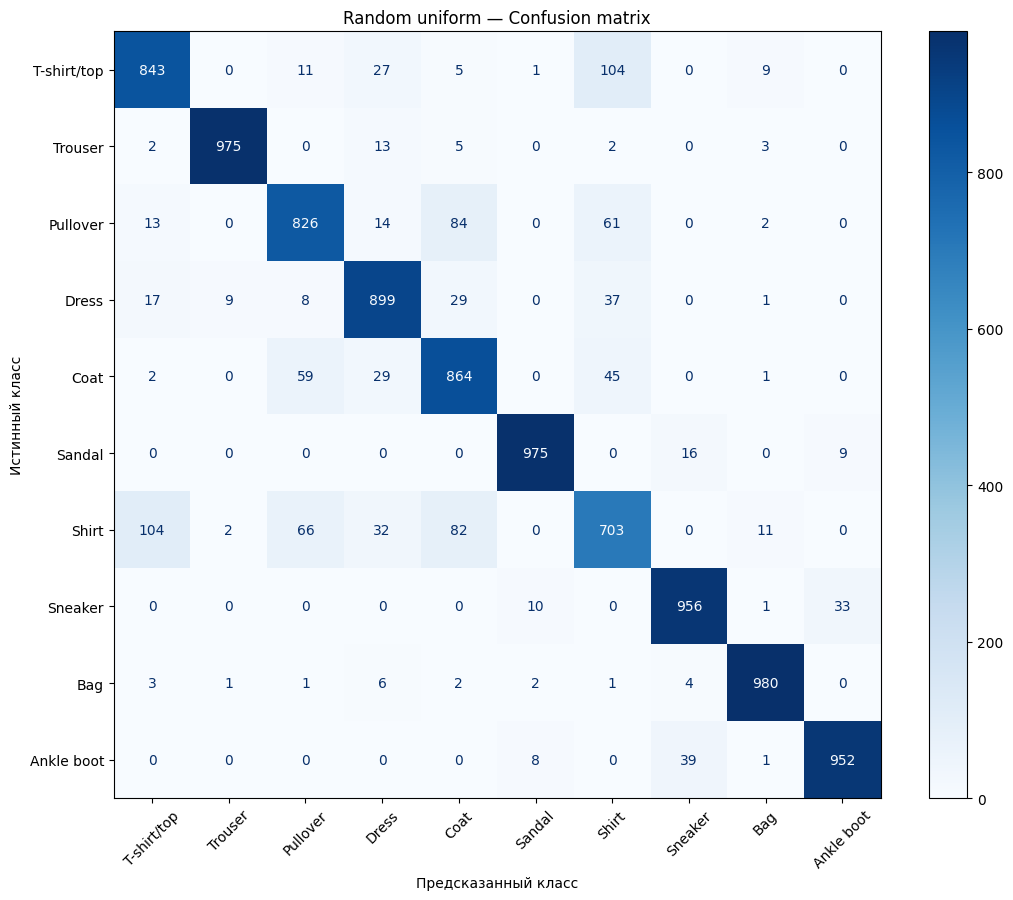


Random uniform завершён.
Добавлено изображений: 3240
Размер train: 14040
Test Accuracy: 0.8973
Macro-F1: 0.8970038815913624
Stage 1 | Epoch 001 | lr: 0.001000 | train loss: 0.8113 | train accuracy: 0.7065 | validation loss: 0.4472 | validation accuracy: 0.8350
Stage 1 | Epoch 002 | lr: 0.001000 | train loss: 0.5247 | train accuracy: 0.8109 | validation loss: 0.3807 | validation accuracy: 0.8613
Stage 1 | Epoch 003 | lr: 0.001000 | train loss: 0.4578 | train accuracy: 0.8306 | validation loss: 0.3196 | validation accuracy: 0.8808
Stage 1 | Epoch 004 | lr: 0.001000 | train loss: 0.4052 | train accuracy: 0.8484 | validation loss: 0.3328 | validation accuracy: 0.8775
Stage 1 | Epoch 005 | lr: 0.001000 | train loss: 0.3820 | train accuracy: 0.8592 | validation loss: 0.3011 | validation accuracy: 0.8893
Stage 1 | Epoch 006 | lr: 0.001000 | train loss: 0.3483 | train accuracy: 0.8700 | validation loss: 0.2953 | validation accuracy: 0.8930
Stage 1 | Epoch 007 | lr: 0.001000 | train loss: 0.32

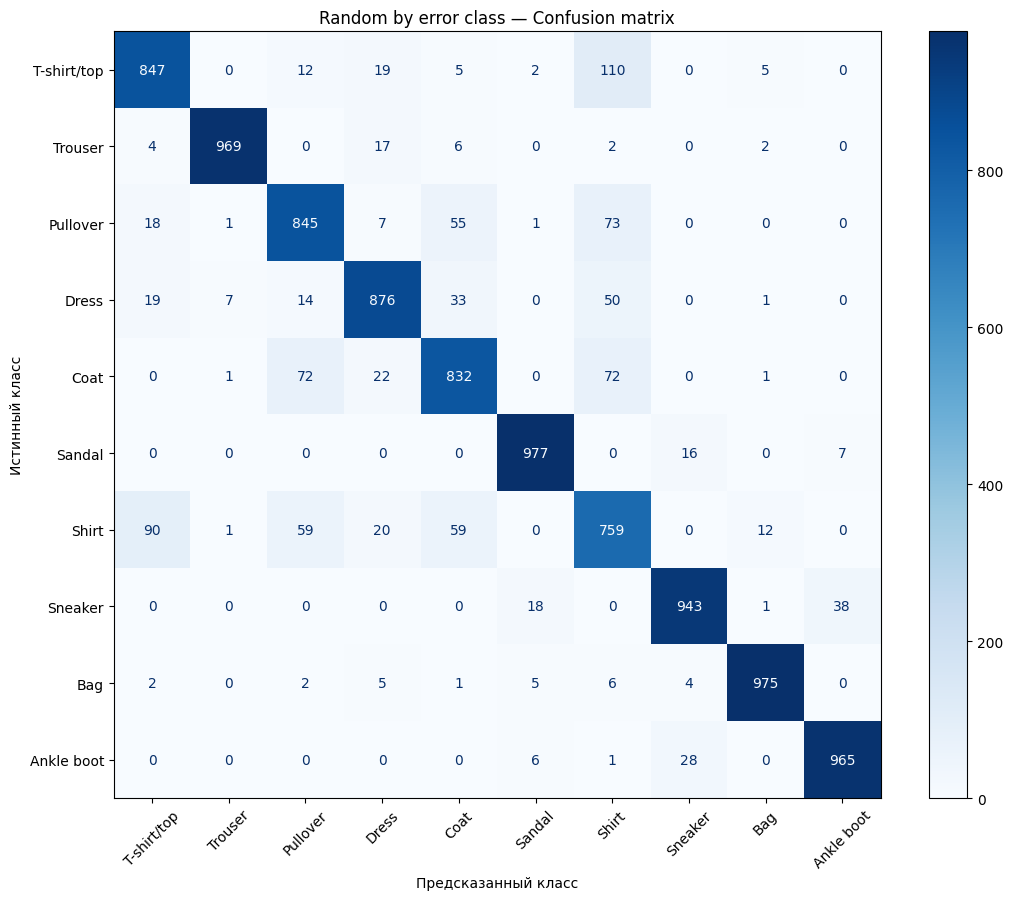


Random by error class завершён.
Добавлено изображений: 3240
Размер train: 14040
Test Accuracy: 0.8988
Macro-F1: 0.8993883510251587


In [90]:
### 37. Запуск случайных стратегий


random_uniform_metrics = (
    run_random_experiment(
        experiment_name=(
            "Random uniform"
        ),
        experiment_folder=(
            "random_uniform"
        ),
        selected_indices=(
            random_uniform_indices
        ),
        selection_method=(
            "uniform_random"
        ),
        selection_seed=(
            RANDOM_UNIFORM_SELECTION_SEED
        ),
        train_seed=RANDOM_TRAIN_SEED,
        selection_metadata={
            "selection_count": int(
                len(random_uniform_indices)
            ),
        },
    )
)


random_error_class_metrics = (
    run_random_experiment(
        experiment_name=(
            "Random by error class"
        ),
        experiment_folder=(
            "random_by_error_class"
        ),
        selected_indices=(
            random_error_class_indices
        ),
        selection_method=(
            "error_proportional_random"
        ),
        selection_seed=(
            RANDOM_CLASS_SELECTION_SEED
        ),
        train_seed=RANDOM_TRAIN_SEED,
        selection_metadata={
            "error_class_counts": (
                error_class_counts.tolist()
            ),
            "class_quotas": (
                random_error_class_quotas.tolist()
            ),
        },
    )
)

### 38. Итоговая таблица всех моделей

In [91]:
### 38. Итоговое сравнение всех моделей


experiment_specs = [
    {
        "name": "Full F baseline",
        "path": (
            experiments_root
            / "baseline"
        ),
    },
    {
        "name": "F-A baseline",
        "path": (
            experiments_root
            / "fa_baseline"
        ),
    },
    {
        "name": "Strategy 1",
        "path": (
            experiments_root
            / "strategy_1_centroid"
        ),
    },
    {
        "name": "Strategy 2",
        "path": (
            experiments_root
            / "strategy_2_hard_examples"
        ),
    },
    {
        "name": "EDNNA +1000",
        "path": (
            experiments_root
            / "ednna"
        ),
    },
    {
        "name": "EDNNA +20%",
        "path": (
            experiments_root
            / "ednna_plus20"
        ),
    },
    {
        "name": "EDNNA +30%",
        "path": (
            experiments_root
            / "ednna_plus30"
        ),
    },
    {
        "name": "Random uniform",
        "path": (
            random_experiments_root
            / "random_uniform"
        ),
    },
    {
        "name": "Random by error class",
        "path": (
            random_experiments_root
            / "random_by_error_class"
        ),
    },
]


comparison_rows = []

for experiment in experiment_specs:
    metrics_path = (
        experiment["path"]
        / "metrics"
        / "test_metrics.json"
    )

    metadata_path = (
        experiment["path"]
        / "selection"
        / "selection_metadata.json"
    )

    if not metrics_path.exists():
        print(
            "Файл не найден:",
            metrics_path,
        )
        continue

    with metrics_path.open(
        "r",
        encoding="utf-8",
    ) as file:
        metrics = json.load(file)

    metadata = {}

    if metadata_path.exists():
        with metadata_path.open(
            "r",
            encoding="utf-8",
        ) as file:
            metadata = json.load(file)

    comparison_rows.append(
        {
            "Модель": experiment["name"],
            "Размер train": metrics.get(
                "train_size"
            ),
            "Добавлено изображений": metrics.get(
                "selected_count"
            ),
            "Validation Accuracy": metrics.get(
                "validation_accuracy"
            ),
            "Test Accuracy": metrics.get(
                "test_accuracy"
            ),
            "Macro-F1": metrics.get(
                "macro_f1"
            ),
            "Причина остановки": (
                metadata.get(
                    "stop_reason"
                )
            ),
        }
    )


comparison_table = pd.DataFrame(
    comparison_rows
)


# Сравнение с базовой F-A-моделью
fa_row = comparison_table[
    comparison_table["Модель"]
    == "F-A baseline"
]

if len(fa_row) > 0:
    fa_accuracy = float(
        fa_row.iloc[0][
            "Test Accuracy"
        ]
    )

    fa_macro_f1 = float(
        fa_row.iloc[0][
            "Macro-F1"
        ]
    )

    comparison_table[
        "Δ Accuracy vs F-A"
    ] = (
        comparison_table["Test Accuracy"]
        - fa_accuracy
    )

    comparison_table[
        "Δ Macro-F1 vs F-A"
    ] = (
        comparison_table["Macro-F1"]
        - fa_macro_f1
    )


comparison_table = comparison_table[
    [
        "Модель",
        "Размер train",
        "Добавлено изображений",
        "Validation Accuracy",
        "Test Accuracy",
        "Macro-F1",
        "Δ Accuracy vs F-A",
        "Δ Macro-F1 vs F-A",
        "Причина остановки",
    ]
]


display(
    comparison_table.style.format(
        {
            "Validation Accuracy": "{:.4f}",
            "Test Accuracy": "{:.4f}",
            "Macro-F1": "{:.6f}",
            "Δ Accuracy vs F-A": "{:+.4f}",
            "Δ Macro-F1 vs F-A": "{:+.6f}",
        },
        na_rep="—",
    ).set_caption(
        "Сравнение всех моделей"
    )
)


comparison_dir = (
    experiments_root
    / "comparison"
)

comparison_dir.mkdir(
    parents=True,
    exist_ok=True,
)

comparison_table.to_csv(
    comparison_dir
    / "all_models_comparison_with_random.csv",
    index=False,
    encoding="utf-8-sig",
)

print()
print(
    "Таблица сохранена в:",
    comparison_dir
    / "all_models_comparison_with_random.csv",
)

,Модель,Размер train,Добавлено изображений,Validation Accuracy,Test Accuracy,Macro-F1,Δ Accuracy vs F-A,Δ Macro-F1 vs F-A,Причина остановки
0,Full F baseline,54000.000000,—,0.9312,0.9200,0.919747,+0.0270,+0.027072,—
1,F-A baseline,10800.000000,—,0.9027,0.8930,0.892675,+0.0000,+0.000000,—
2,Strategy 1,—,—,0.9013,0.8940,0.893462,+0.0010,+0.000787,—
3,Strategy 2,—,—,0.9037,0.8947,0.893772,+0.0017,+0.001097,—
4,EDNNA +1000,11800.000000,1000.000000,—,0.8927,0.893094,-0.0003,+0.000419,—
5,EDNNA +20%,12960.000000,2160.000000,—,0.8996,0.899315,+0.0066,+0.006640,—
6,EDNNA +30%,14040.000000,3240.000000,—,0.9000,0.899794,+0.0070,+0.007119,—
7,Random uniform,14040.000000,3240.000000,0.9122,0.8973,0.897004,+0.0043,+0.004329,fixed_budget
8,Random by error class,14040.000000,3240.000000,0.9123,0.8988,0.899388,+0.0058,+0.006713,fixed_budget



Таблица сохранена в: D:\Учеба\fashion-mnist-cnn-experiments\experiments\fashion_mnist\comparison\all_models_comparison_with_random.csv


### 39. Сравнение направленных ошибок

In [92]:
### 39. Сравнение направленных ошибок


direction_experiments = [
    {
        "Модель": "F-A baseline",
        "path": (
            experiments_root
            / "fa_baseline"
        ),
    },
    {
        "Модель": "EDNNA +1000",
        "path": (
            experiments_root
            / "ednna"
        ),
    },
    {
        "Модель": "EDNNA +20%",
        "path": (
            experiments_root
            / "ednna_plus20"
        ),
    },
    {
        "Модель": "EDNNA +30%",
        "path": (
            experiments_root
            / "ednna_plus30"
        ),
    },
    {
        "Модель": "Random uniform",
        "path": (
            random_experiments_root
            / "random_uniform"
        ),
    },
    {
        "Модель": "Random by error class",
        "path": (
            random_experiments_root
            / "random_by_error_class"
        ),
    },
]


direction_rows = []

for experiment in direction_experiments:
    confusion_path = (
        experiment["path"]
        / "metrics"
        / "confusion_matrix.csv"
    )

    if not confusion_path.exists():
        continue

    confusion_df = pd.read_csv(
        confusion_path,
        index_col=0,
    )

    shirt_to_tshirt = int(
        confusion_df.loc[
            "Shirt",
            "T-shirt/top",
        ]
    )

    tshirt_to_shirt = int(
        confusion_df.loc[
            "T-shirt/top",
            "Shirt",
        ]
    )

    direction_rows.append(
        {
            "Модель": experiment["Модель"],
            "Shirt → T-shirt/top": (
                shirt_to_tshirt
            ),
            "T-shirt/top → Shirt": (
                tshirt_to_shirt
            ),
            "Всего ошибок между классами": (
                shirt_to_tshirt
                + tshirt_to_shirt
            ),
        }
    )


direction_table = pd.DataFrame(
    direction_rows
)


display(
    direction_table.style.set_caption(
        "Сравнение направленных ошибок"
    )
)


direction_table.to_csv(
    comparison_dir
    / "directed_errors_comparison_with_random.csv",
    index=False,
    encoding="utf-8-sig",
)

,Модель,Shirt → T-shirt/top,T-shirt/top → Shirt,Всего ошибок между классами
0,F-A baseline,120,103,223
1,EDNNA +1000,103,121,224
2,EDNNA +20%,114,103,217
3,EDNNA +30%,90,105,195
4,Random uniform,104,104,208
5,Random by error class,90,110,200


### Вывод

В эксперименте были сравнены базовые модели, стратегии добавления изображений, EDNNA и два варианта случайного отбора.

Модель, обученная на полной выборке F из 54 000 изображений, показала наилучшее качество: Test Accuracy составила 0,9200, а Macro-F1 — 0,9197. Базовая модель, обученная на сокращённой выборке F-A из 10 800 изображений, получила Test Accuracy 0,8930 и Macro-F1 0,8927.

Добавление 1000 изображений с помощью EDNNA практически не изменило общую точность. Однако при увеличении выборки на 20% качество повысилось до Test Accuracy 0,8996 и Macro-F1 0,8993. При увеличении выборки на 30% результат стал ещё немного лучше: Test Accuracy составила 0,9000, а Macro-F1 — 0,8998. Таким образом, по сравнению с базовой моделью F-A прирост составил 0,70 процентного пункта по Accuracy и 0,71 процентного пункта по Macro-F1.

Для сравнения были обучены две модели со случайным отбором такого же количества изображений. Равномерный случайный отбор дал Test Accuracy 0,8973, а случайный отбор с распределением изображений по долям ошибок классов — 0,8988. EDNNA с увеличением выборки на 30% показал более высокий результат, чем обе случайные стратегии. Это показывает, что улучшение связано не только с увеличением объёма обучающей выборки, но и с принципом отбора объектов.

Наиболее сложными для модели остаются классы Shirt и T-shirt/top. Для базовой модели суммарное количество ошибок между этими классами составило 223. После применения EDNNA и добавления 30% изображений это количество уменьшилось до 195. В частности, количество ошибок по направлению Shirt → T-shirt/top уменьшилось с 120 до 90.

Таким образом, EDNNA оказался наиболее эффективной стратегией среди рассмотренных методов расширения выборки. Наилучший результат был получен при увеличении F-A на 30%. При этом целевое значение validation accuracy, равное 0,92, достигнуто не было, поэтому алгоритм завершился после достижения установленного бюджета в 3240 дополнительных изображений.

Разница между EDNNA и случайным отбором по долям ошибок оказалась небольшой, поэтому для окончательного подтверждения преимущества EDNNA желательно повторить эксперименты с несколькими значениями seed. Полученные результаты относятся к одному запуску каждой стратегии.